<center><h1>Timmala_Karan_HW4</h1></center>
<br>
<br>

Name: Karan Timmala
<br>
Github Username: karantimmala
<br>
USC ID: 1373267232

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Download the AReM data from: https://archive.ics.uci.edu/ml/datasets/
Activity+Recognition+system+based+on+Multisensor+data+fusion+\%28AReM\
%29 . The dataset contains 7 folders that represent seven types of activities. In
each folder, there are multiple files each of which represents an instant of a human
performing an activity.1 Each file containis 6 time series collected from activities
of the same person, which are called avg rss12, var rss12, avg rss13, var rss13,
vg rss23, and ar rss23. There are 88 instances in the dataset, each of which contains 6 time series and each time series has 480 consecutive values.

Package imports

Get the AReM Data Set

In [1]:
# ================================================================
# Required Package Imports
# ================================================================

import os
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import StratifiedKFold
from sklearn.utils import resample
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.exceptions import ConvergenceWarning

### (b) Test and Train Data

Keep datasets 1 and 2 in folders bending1 and bending 2, as well as datasets 1,
2, and 3 in other folders as test data and other datasets as train data.

In [2]:
# DIRECTORY VERIFICATION & FILE PARSING SETUP

# Define the root path where the unzipped AReM dataset is located on your local machine
root_dir = Path("../data/AReM/")

# Check if the root directory actually exists before proceeding
if not root_dir.exists():
    raise FileNotFoundError(f"Directory {root_dir} was not found.")
print("Directory Verification Successful!!")

# Define the 7 target categories/activity folders mandatory for this dataset benchmark
target_categories = {"bending1","bending2","cycling","lying","sitting","standing","walking"}

# Automatically scan subfolders recursively using rglob to locate where the activity folders reside
for match_item in root_dir.rglob("bending1"):
    base_folder = match_item.parent
    
    # Collect all subdirectory names present inside the candidate parent directory
    found_subdirs = {
        sub_elem.name
        for sub_elem in base_folder.iterdir()
        if sub_elem.is_dir()
    }
    
    # If all 7 target activity folders are present in this directory, set it as dataset_root and stop searching
    if target_categories.issubset(found_subdirs):
        dataset_root = base_folder
        break

# Define ordered lists for activities and columns for standardizing data frames
activity_list = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
feature_columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def extract_index(path_obj):
    """Extracts the dataset number integer from the filename (e.g., dataset1.csv -> 1)."""
    search_res = re.search(r"dataset(\d+)", path_obj.stem)
    if search_res is None:
        raise ValueError(f"Unrecognized file naming: {path_obj.name}")
    return int(search_res.group(1))


def determine_partition(act_name, idx_num):
    """Assigns train/test split based on benchmark rules (datasets 1-2 for bending, 1-3 for others)."""
    # Bending activities use datasets 1 and 2 for testing, and the rest for training
    if act_name in ["bending1", "bending2"]:
        if idx_num in [1, 2]:
            return "test"
        return "train"
    
    # All other activities use datasets 1, 2, and 3 for testing, and the rest for training
    if idx_num in [1, 2, 3]:
        return "test"
    return "train"


def load_sensor_file(file_path):
    """Reads raw CSV time-series sensor data, cleans text lines, handles missing tokens, and performs linear interpolation."""
    collected_rows = []
    
    # Open and read the text file line by line
    with open(file_path, "r") as reader:
        for single_line in reader:
            cleaned_line = single_line.strip()
            
            # Skip empty lines or comment lines starting with '#'
            if not cleaned_line or cleaned_line.startswith("#"):
                continue
                
            # Remove trailing commas that might cause parsing artifacts
            cleaned_line = cleaned_line.rstrip(",")
            
            # Split line elements by comma and/or arbitrary whitespace
            tokens = re.split(r"\s*,\s*|\s+", cleaned_line)
            
            # Keep only lines that contain the exact expected number of sensor columns (7)
            if len(tokens) == 7:
                collected_rows.append(tokens)

    # Convert the parsed list of rows into a structured Pandas DataFrame
    df_frame = pd.DataFrame(
        collected_rows,
        columns=feature_columns
    )
    
    # Force data types to numeric, converting unparseable characters to NaN values
    df_frame = df_frame.apply(
        pd.to_numeric,
        errors="coerce"
    )
    
    # Clean up rows containing NaN values and remove duplicate timestamps
    df_frame = df_frame.dropna()
    df_frame = df_frame.drop_duplicates(subset="time")

    # Standardize time steps uniformly across time-series instances (0ms to 120,000ms at 250ms intervals)
    target_time_axis = np.arange(
        start=0,
        stop=120000,
        step=250
    )
    
    # Reindex the DataFrame to match the uniform time axis and handle any gaps using linear interpolation
    df_frame = df_frame.set_index("time")
    df_frame = df_frame.reindex(target_time_axis)
    
    sig_cols = feature_columns[1:]
    df_frame[sig_cols] = df_frame[sig_cols].interpolate(
        method="linear",
        limit_direction="both"
    )
    
    # Reset index back to a standard column format
    df_frame.index.name = "time"
    df_frame = df_frame.reset_index()
    return df_frame
    

# Initialize a tracking list to store metadata records for every CSV instance
log_entries = []

# Loop iteratively through each activity folder and parse each matching dataset CSV file
for act in activity_list:
    target_dir = dataset_root / act
    
    # Sort files numerically using the helper extraction function
    csv_files = sorted(
        target_dir.glob("dataset*.csv"),
        key=extract_index
    )
    for current_file in csv_files:
        file_idx = extract_index(current_file) 
        # Load, clean, and interpolate the time-series file
        processed_df = load_sensor_file(current_file)
        
        # Append metadata and record information for tracking/validation summary
        log_entries.append({
            "activity": act,
            "dataset": file_idx,
            "split": determine_partition(act, file_idx),
            "observations": len(processed_df),
            "file": current_file
        })

# Compile the audit records into a summary DataFrame to confirm correct instance count and splits
summary_validation = pd.DataFrame(log_entries)

print("TOTAL INSTANCES:", len(summary_validation))
print("---------------------------------")
print(summary_validation["activity"].value_counts())
print("---------------------------------")
print(summary_validation["split"].value_counts())
print("---------------------------------")
print(summary_validation["observations"].value_counts())

Directory Verification Successful!!
TOTAL INSTANCES: 88
---------------------------------
activity
cycling     15
lying       15
sitting     15
standing    15
walking     15
bending1     7
bending2     6
Name: count, dtype: int64
---------------------------------
split
train    69
test     19
Name: count, dtype: int64
---------------------------------
observations
480    88
Name: count, dtype: int64


### (c) Feature Extraction

#### i. Research what types of time-domain features are usually used in time series classification and list them (examples are minimum, maximum, mean, etc).


Min & Max: Mark the lower and upper boundaries of the signal amplitude.

Mean & Median: Represent central trend metrics to establish the signal's baseline level.

Standard Deviation & Variance: Quantify variability and fluctuation in signal energy or amplitude.

Percentiles / Interquartile Range (IQR): Measure data spread at given thresholds (e.g., 25th and 75th percentiles), offering outlier-resistant dispersion metrics.

Skewness: Gauges the degree of asymmetry in the data distribution around the mean.

Kurtosis: Indicates the presence of heavy tails or extreme outlier values in the signal.

Mean Absolute Deviation (MAD): Average distance of points from the mean.

Root Mean Square (RMS): Quantifies the overall power/magnitude of the signal.

Entropy: Quantifies the degree of complexity, regularity, or randomness in the sequence.



#### ii. Extract the time-domain features minimum, maximum, mean, median, standard deviation, first quartile, and third quartile for all of the 6 time series in each instance. You are free to normalize/standardize features or use them directly.


In [3]:
# =====================================================================
# FEATURE EXTRACTION (TIME-DOMAIN METRICS)
# =====================================================================

def compute_summary_metrics(df_source):
    """
    Computes time-domain statistical metrics (min, max, mean, median, standard deviation, 
    1st quartile, and 3rd quartile) for each of the 6 sensor time-series channels.
    """
    metrics_dict = {}
    
    # Exclude the first column ('time') and process only the 6 sensor columns
    sig_fields = feature_columns[1:]

    # Iterate through each sensor column, assigning a numerical index starting from 1
    for idx_num, col_label in enumerate(sig_fields, start=1):
        series_data = df_source[col_label]
        
        # Calculate time-domain summary statistics for the current sensor channel
        metrics_dict[f"min{idx_num}"] = series_data.min()
        metrics_dict[f"max{idx_num}"] = series_data.max()
        metrics_dict[f"mean{idx_num}"] = series_data.mean()
        metrics_dict[f"median{idx_num}"] = series_data.median()
        metrics_dict[f"std{idx_num}"] = series_data.std(ddof=1)  # Sample standard deviation (N-1 degrees of freedom)
        metrics_dict[f"1st_quart{idx_num}"] = series_data.quantile(0.25)  # 25th percentile
        metrics_dict[f"3rd_quart{idx_num}"] = series_data.quantile(0.75)  # 75th percentile
        
    return metrics_dict


# Initialize a list to hold the computed feature dictionaries for all dataset instances
record_collection = []

# Loop through each activity folder and file to extract summary features for all 88 instances
for act_name in activity_list:
    target_dir = dataset_root / act_name
    
    # Retrieve and numerically sort all dataset CSV files in the current activity directory
    csv_collection = sorted(
        target_dir.glob("dataset*.csv"),
        key=extract_index
    )
    
    for single_csv in csv_collection:
        # Extract metadata identifiers for the current file
        file_id = extract_index(single_csv)
        
        # Load, clean, and interpolate the time-series sensor data
        processed_frame = load_sensor_file(single_csv)
        
        # Compute the time-domain metrics dictionary for all 6 sensor channels
        stat_summary = compute_summary_metrics(processed_frame)
        
        # Append instance identification metadata to the summary dictionary
        stat_summary["instance"] = f"{act_name}_dataset{file_id}"
        stat_summary["activity"] = act_name
        stat_summary["dataset"] = file_id
        stat_summary["split"] = determine_partition(act_name, file_id)
        
        # Store the completed dictionary record in the collection list
        record_collection.append(stat_summary)

# Convert the compiled list of records into a comprehensive pandas DataFrame
extracted_features = pd.DataFrame(record_collection)

# Define the sequence of statistical indicators to build structured feature column names
stat_indicators = [
    "min",
    "max",
    "mean",
    "median",
    "std",
    "1st_quart",
    "3rd_quart"
]

# Generate the complete, ordered list of 42 feature column names (7 metrics x 6 channels)
generated_feature_names = []
for chan_num in range(1, 7):
    for indicator in stat_indicators:
        generated_feature_names.append(f"{indicator}{chan_num}")

# Reorder the DataFrame columns to place metadata columns first, followed by the generated sensor features
extracted_features = extracted_features[
    ["instance", "activity", "dataset", "split"] + generated_feature_names
]

# Sort the final dataset rows by activity name and dataset number, then reset the index
extracted_features = extracted_features.sort_values(
    ["activity", "dataset"]
).reset_index(drop=True)

# Preview the first 5 rows of the extracted feature table
extracted_features.head()

,instance,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1_dataset2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1_dataset3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1_dataset4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1_dataset5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [4]:
# MATRIX DIMENSIONS & MISSING VALUE CHECK
matrix_view = extracted_features[
    ["instance"] + generated_feature_names
]
print("TABLE DIMENSIONS", matrix_view.shape)
matrix_view

TABLE DIMENSIONS (88, 43)


,instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,bending1_dataset1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,bending1_dataset2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,bending1_dataset3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,bending1_dataset4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,bending1_dataset5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking_dataset11,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,walking_dataset12,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,walking_dataset13,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,walking_dataset14,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


In [5]:
# BOOTSTRAP CONFIDENCE INTERVAL ESTIMATION
extracted_features["split"].value_counts()
null_tally = extracted_features[generated_feature_names].isna().sum().sum()
print("MISSING VALUE COUNT:", null_tally)

MISSING VALUE COUNT: 0


#### iii. Standard Deviation Estimate the standard deviation of each of the time-domain features you extracted from the data. Then, use Python’s bootstrapped or any other method to build a 90% bootsrap confidence interval for the standard deviation of each feature.

In [6]:
def compute_bootstrap_bounds(arr_data, total_samples=10000, init_seed=42):
    """Calculates a 90% bootstrap confidence interval for standard deviation using empirical resampling."""
    rnd_engine = np.random.default_rng(init_seed)
    stat_array = np.empty(total_samples)
    for idx in range(total_samples):
        resample_subset = rnd_engine.choice(
            arr_data,
            size=len(arr_data),
            replace=True
        )
        stat_array[idx] = np.std(resample_subset, ddof=1)
    lower_limit = np.percentile(stat_array, 5)
    upper_limit = np.percentile(stat_array, 95)
    return lower_limit, upper_limit

ci_records = []

# Generate bootstrap intervals for each extracted time-domain feature
for pos_idx, col_name in enumerate(generated_feature_names):
    column_array = extracted_features[col_name].to_numpy()
    sample_std_dev = np.std(column_array, ddof=1)
    lower_val, upper_val = compute_bootstrap_bounds(
        column_array,
        total_samples=10000,
        init_seed=42 + pos_idx
    )
    ci_records.append({
        "FEATURE": col_name,
        "STANDARD DEVIATION": sample_std_dev,
        "LOWER BOUND": lower_val,
        "UPPER BOUND": upper_val
    })
bootstrap_summary_df = pd.DataFrame(ci_records)
bootstrap_summary_df = bootstrap_summary_df.round(3)
bootstrap_summary_df

,FEATURE,STANDARD DEVIATION,LOWER BOUND,UPPER BOUND
0,min1,9.570,8.236,10.774
1,max1,4.394,3.345,5.290
2,mean1,5.336,4.711,5.877
3,median1,5.440,4.796,5.993
4,std1,1.772,1.573,1.950
5,1st_quart1,6.154,5.574,6.643
6,3rd_quart1,5.139,4.336,5.830
7,min2,0.000,0.000,0.000
8,max2,5.063,4.622,5.408
9,mean2,1.574,1.396,1.706


#### iv. Use your judgement to select the three most important time-domain features (one option may be min, mean, and max).

##### Based on my judgement, I selected Mean, Maximum and Standard Deviation as the three most important time-domain features.
##### **Maximum:** The maximum value records the highest intensity peak within a given time frame. Even when different activities share similar average values, their peak outputs often differ sharply, allowing this feature to highlight sudden, high-intensity movements.
##### **Mean:** The mean establishes the signal's core baseline over time. Because distinct physical activities typically function at varying baseline intensities, this metric makes it easy to separate actions with sustained high intensity from those with lower overall activity levels.
##### **Standard Deviation:** Standard deviation measures the degree of variation and instability within the signal. Continuous physical movement generally causes greater signal fluctuation, while stationary positions keep the signal stable, making variability a key metric for distinguishing between active and idle states.

##### Together, these three parameters capture central tendency, variance, and peak values, providing a concise yet effective feature set to differentiate time-series signal behaviors. 

# 2. ISLR 3.7.4

### I collect a set of data (n = 100 observations) containing a single predictor and a quantitative response. I then fit a linear regression model to the data, as well as a separate cubic regression, i.e. Y = β0 + β1X + β2X2 + β3X3 + ϵ.


### (a) Suppose that the true relationship between X and Y is linear, i.e. Y = β0 + β1X + ϵ. Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.

##### Ans : When the true underlying relationship between $X$ and $Y$ is linear, a linear regression model accurately captures the underlying process. Nevertheless, a cubic regression model inherently encompasses the linear model when its higher-order coefficients ($\beta_2$ and $\beta_3$) equal zero. Because of these extra parameters, the cubic model possesses greater capacity to fit the noise in the training set. Consequently, its training residual sum of squares (RSS) will always be lower than or equal to that of the linear model, as the increased flexibility allows it to fit the training data more tightly even if the actual pattern is linear.

### **(b) Answer (a) using test rather than training RSS.**


##### Ans : When evaluating test RSS, the outcome shifts in favor of the simpler model. Because the actual data-generating process is linear, the linear regression achieves minimal bias without introducing redundant complexity. Conversely, the cubic regression introduces extra degrees of freedom, which inflates the model's variance and leaves it prone to overfitting by fitting random noise present in the training set. Consequently, the linear model is anticipated to achieve a lower test RSS compared to the cubic model.

### 
**(c) Suppose that the true relationship between X and Y is not linear, but we don’t know how far it is from linear. Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.**

##### Ans : When the actual relationship between $X$ and $Y$ is non-linear, the cubic regression provides greater flexibility than the linear model. Since the cubic specification encompasses the linear model as a subset where $\beta_2 = \beta_3 = 0$, it can adapt to the training observations at least as effectively as the simpler model. Consequently, the cubic regression will yield a training RSS that is less than or equal to that of the linear model.

### **(d)Answer (c) using test rather than training RSS.**

##### Ans : When evaluating test RSS under non-linear conditions, there is insufficient information to conclusively determine which model will outperform the other. If the true data-generating process is only slightly non-linear, the linear regression may yield better generalization due to its minimal model variance. Conversely, if the non-linear structure is pronounced, the cubic regression's ability to significantly lower estimation bias could outweigh its higher variance, resulting in a superior test RSS. Consequently, relative performance depends on the underlying bias–variance tradeoff.

# END OF HW3

## Time Series Classification Part 2: Binary and Multiclass Classification
## (a)Binary Classification Using Logistic Regression
#### (i)i.Assume that you want to use the training set to classify bending from other activities, i.e. you have a binary classification problem. Depict scatter plots of the features you specified in 1(c)iv extracted from time series 1, 2, and 6 of each instance, and use color to distinguish bending vs. other activities. (See p. 129 of the textbook)

Scatter plots of selected features from time series 1, 2, and 6
Training set size: 69
Bending: Class 1
Other activities: Class 0


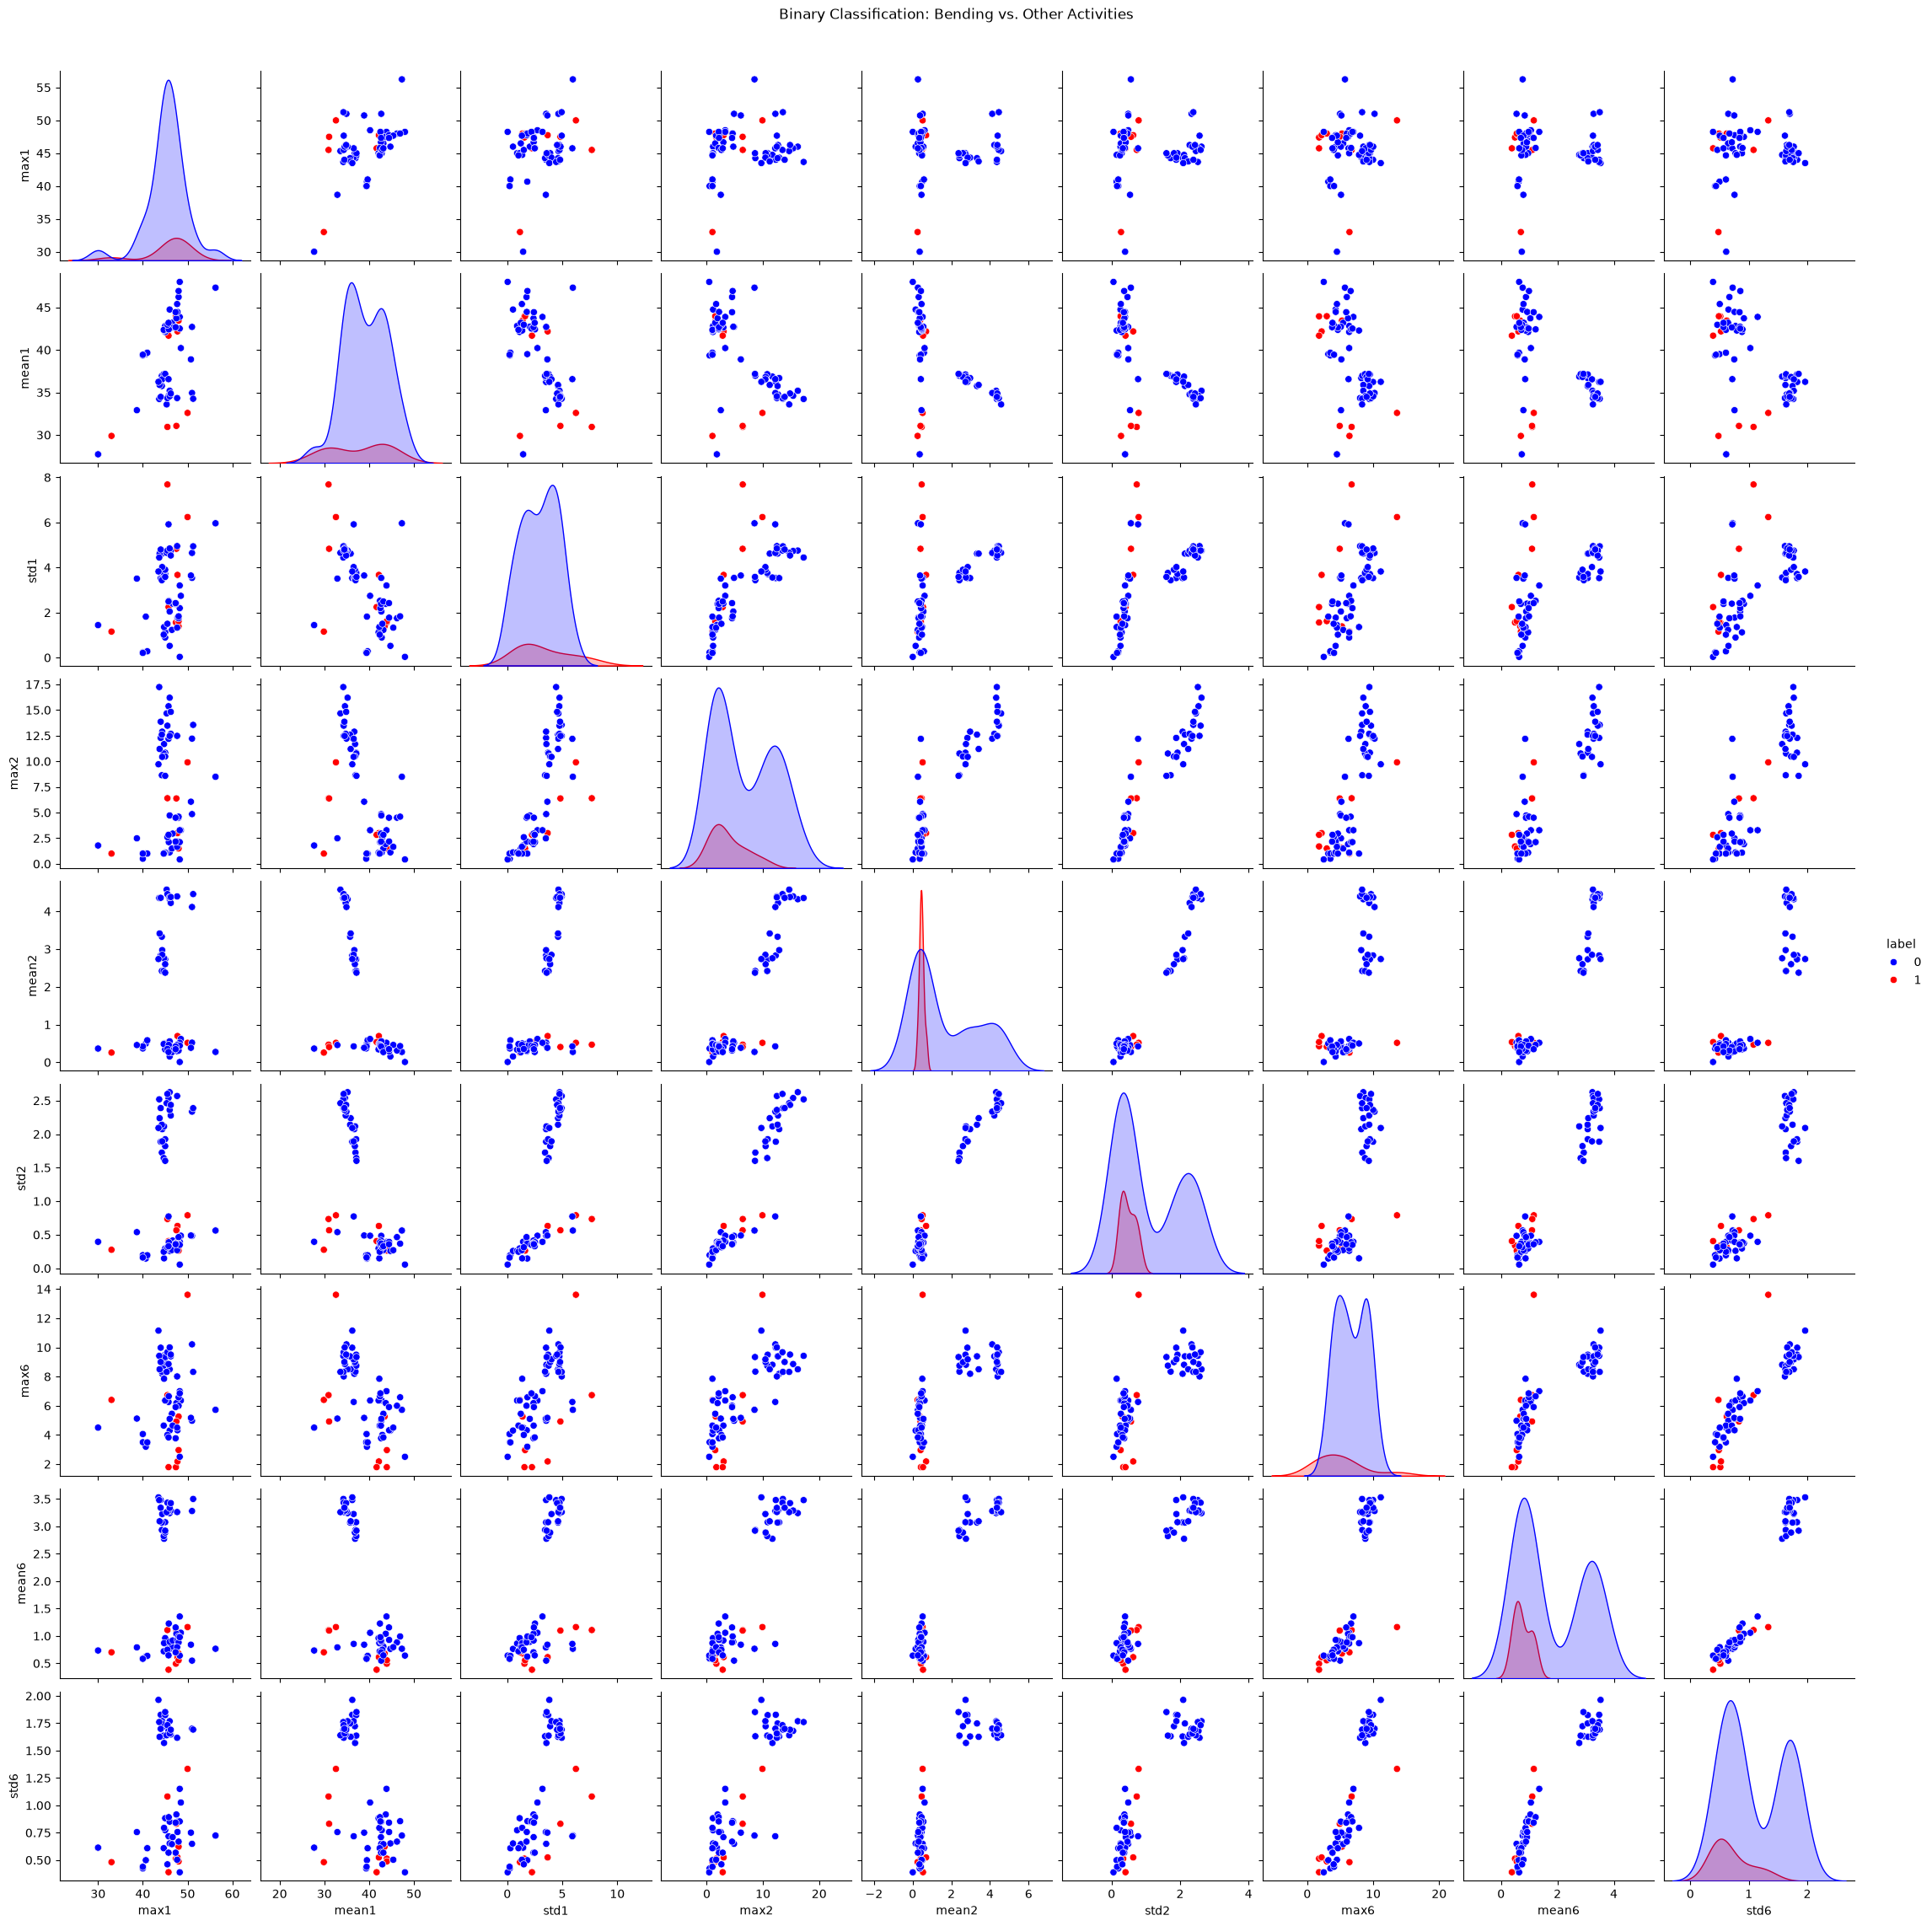

In [7]:
# 2.0.1 (i) Scatter Plots of Selected Features for Binary Classification

# Use only the training instances
train_dataset_new = extracted_features[
    extracted_features["split"] == "train"
].copy()

# Assign binary class labels: Bending = 1, Other Activities = 0
train_dataset_new["label"] = train_dataset_new["activity"].isin(
    ["bending1", "bending2"]
).astype(int)

# Select the features chosen in Question 1(c)(iv):
# Maximum, Mean, and Standard Deviation for time series 1, 2, and 6
extr_columns = [
    f"{feature}{i}"
    for i in [1, 2, 6]
    for feature in ["max", "mean", "std"]
]

extr_columns.append("label")

extr_train_dataset_new = train_dataset_new[extr_columns].copy()

# Display the class information
print("Scatter plots of selected features from time series 1, 2, and 6")
print("Training set size:", len(extr_train_dataset_new))
print("Bending: Class 1")
print("Other activities: Class 0")

# Generate scatter plots and use colors to distinguish the two classes
sns.pairplot(data=extr_train_dataset_new,vars=extr_columns[:-1],hue="label",palette={0: "blue", 1: "red"})

plt.suptitle("Binary Classification: Bending vs. Other Activities",y=1.02)
plt.show()

### (ii)Break each time series in your training set into two (approximately) equal length time series. Now instead of 6 time series for each of the training instances, you have 12 time series for each training instance. Repeat the experiment in 4(a)i, i.e depict scatter plots of the features extracted from both parts of the time series 1,2, and 6. Do you see any considerable difference in the results with those of 4(a)i?

Scatter plots of features from both halves of time series 1, 2, and 6
Number of training instances: 69
Bending: Class 1
Other activities: Class 0


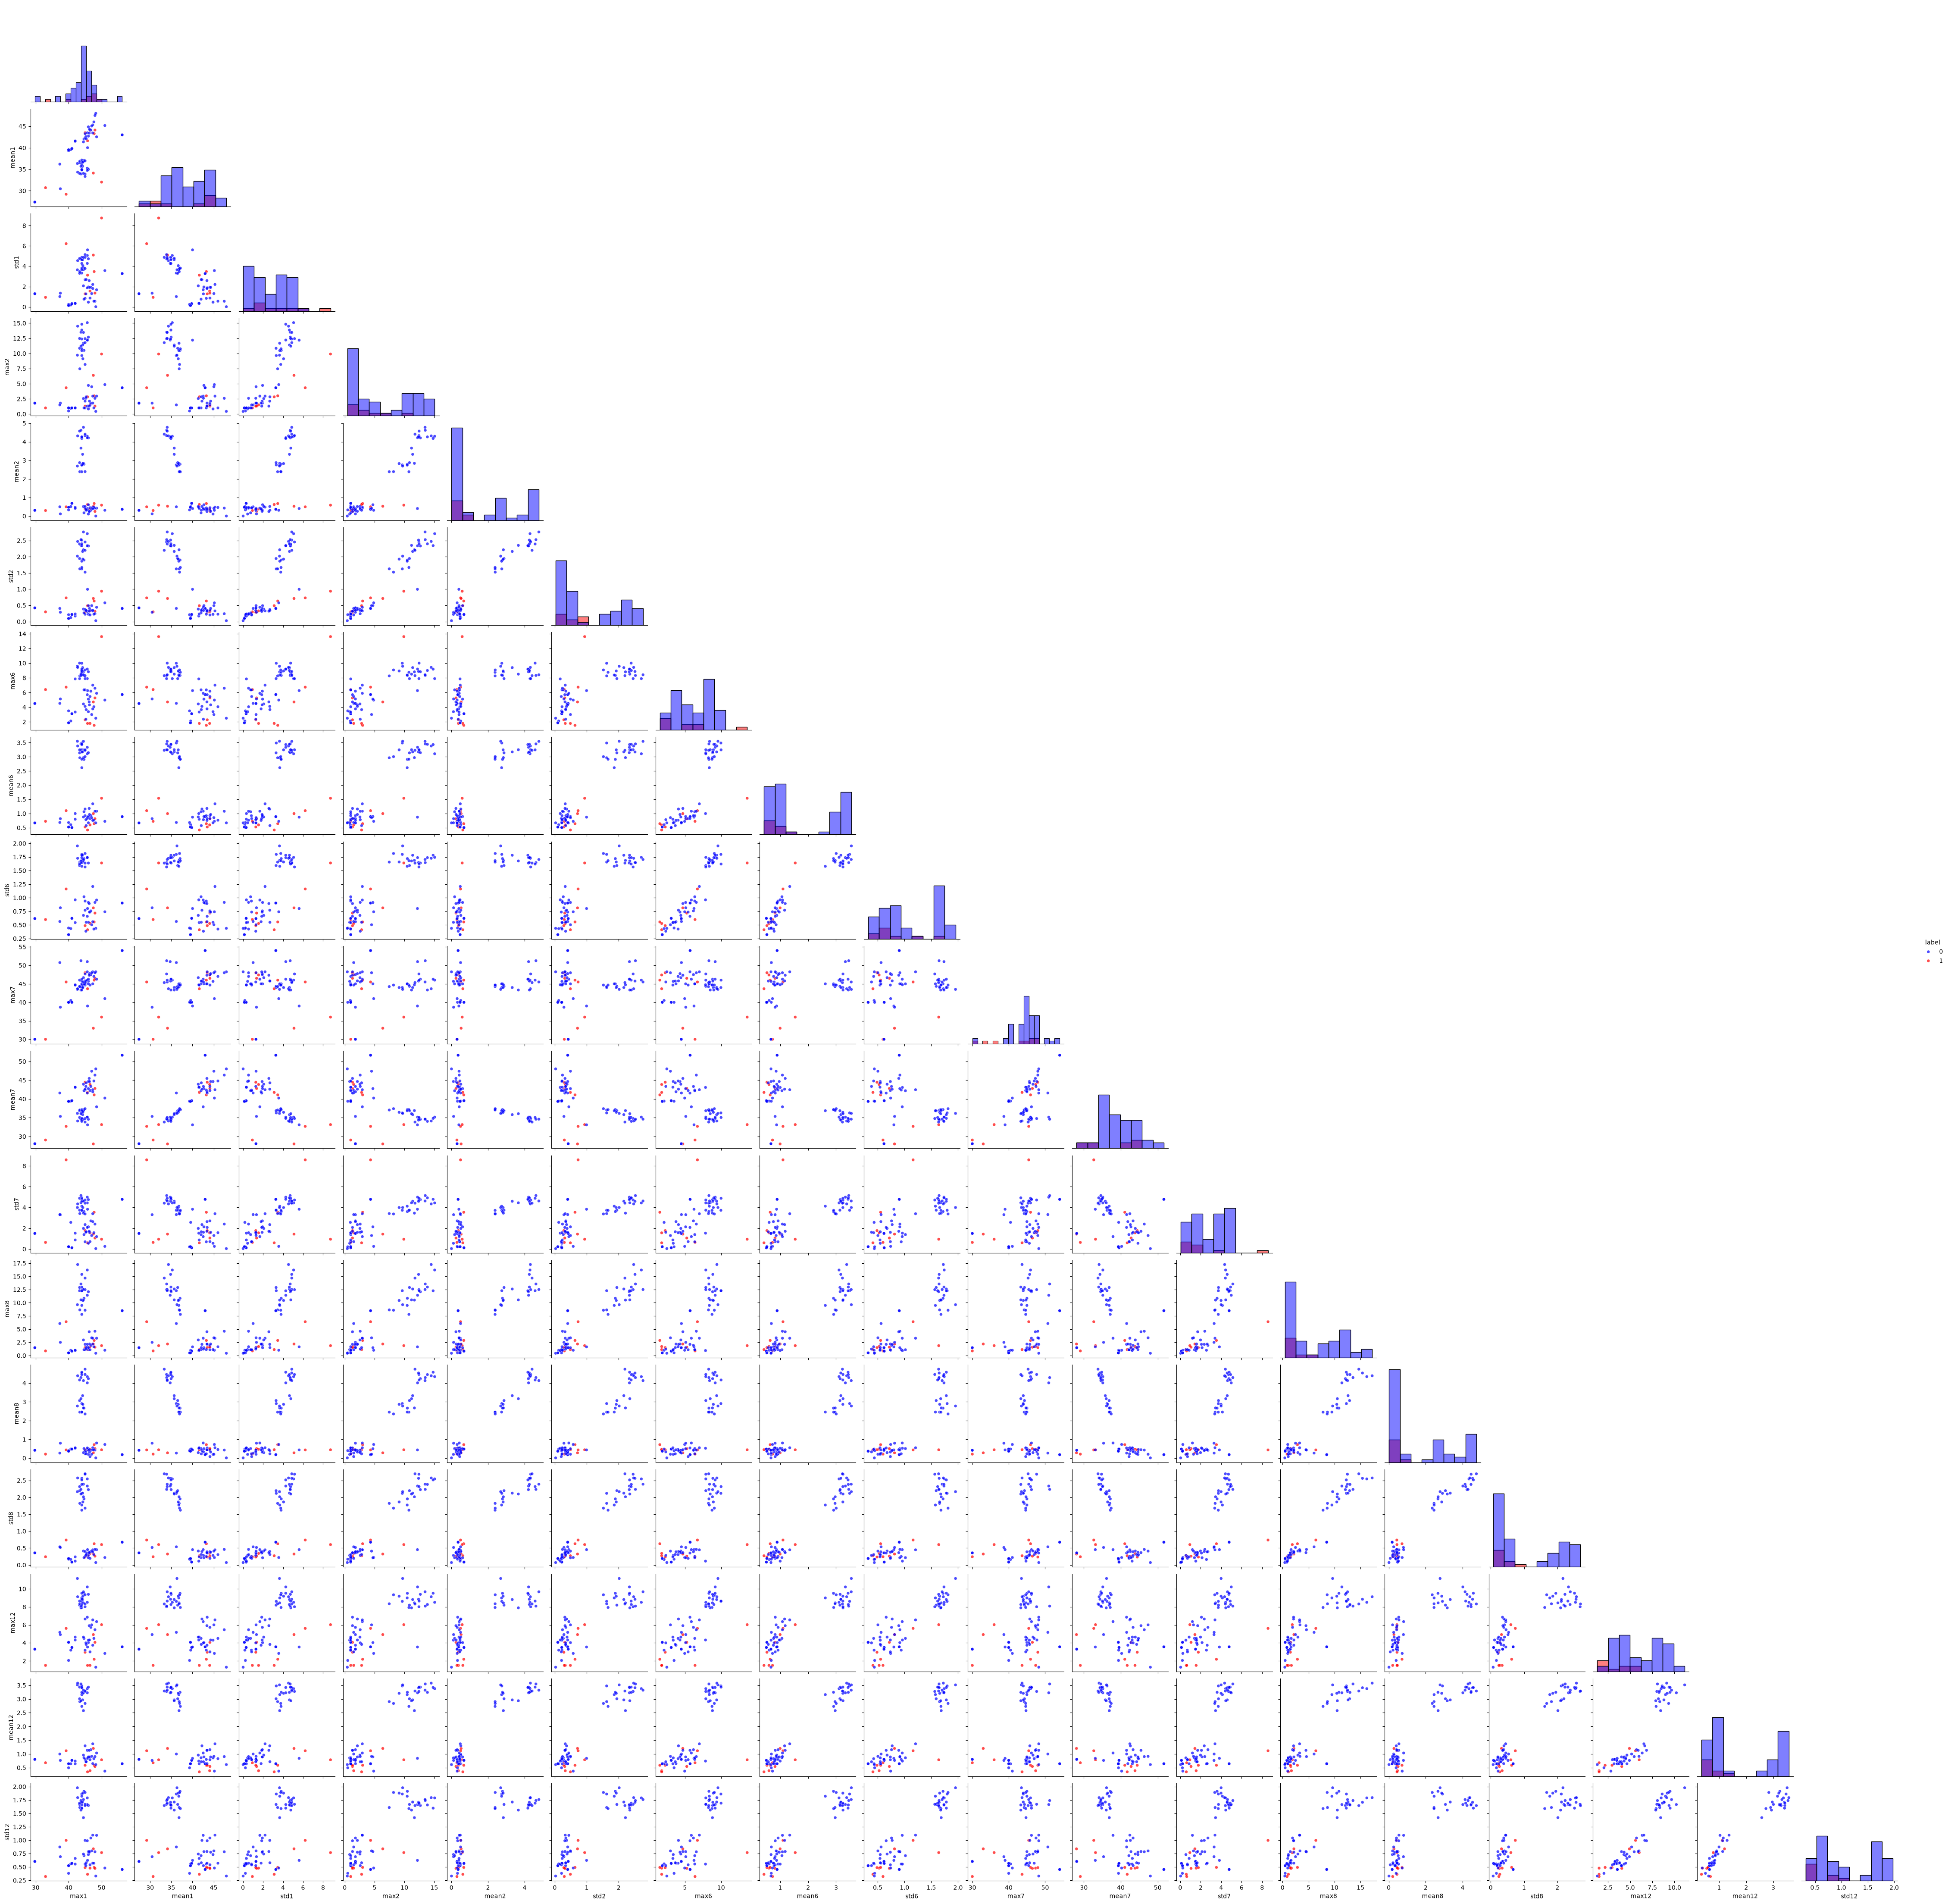

In [8]:
# 2.0.1 (ii) - Scatter plots after splitting each time series into two halves

# Store the feature values for the training instances
split_feature_records = []

# Only use the training data
for act_name in activity_list:
    target_dir = dataset_root / act_name

    csv_collection = sorted(
        target_dir.glob("dataset*.csv"),
        key=extract_index
    )

    for single_csv in csv_collection:
        file_id = extract_index(single_csv)

        # Keep only training instances
        if determine_partition(act_name, file_id) != "train":
            continue

        # Load and clean the original time-series data
        processed_frame = load_sensor_file(single_csv)

        row = {
            "instance": f"{act_name}_dataset{file_id}",
            "activity": act_name
        }

        # Split each of the six sensor time series into two halves
        for sensor_idx, sensor_col in enumerate(feature_columns[1:], start=1):

            sensor_values = processed_frame[sensor_col].to_numpy(
                dtype=float
            )

            first_half, second_half = np.array_split(sensor_values, 2)

            # First half: feature indices 1 through 6
            # Second half: feature indices 7 through 12
            for half_idx, segment in enumerate(
                [first_half, second_half]
            ):
                feature_idx = sensor_idx + (half_idx * 6)

                row[f"max{feature_idx}"] = np.max(segment)
                row[f"mean{feature_idx}"] = np.mean(segment)
                row[f"std{feature_idx}"] = np.std(
                    segment, ddof=1
                )

        # Bending = 1; all other activities = 0
        row["label"] = int(
            act_name in ["bending1", "bending2"]
        )

        split_feature_records.append(row)


# Create the training feature DataFrame
train_dataset_new_split = pd.DataFrame(split_feature_records)

# Select features from sensor series 1, 2, and 6 in both halves.
# First-half indices: 1, 2, 6
# Second-half indices: 7, 8, 12
selected_indices = [1, 2, 6, 7, 8, 12]

extr_columns = [
    f"{feature}{i}"
    for i in selected_indices
    for feature in ["max", "mean", "std"]
]

extr_columns.append("label")

extr_train_dataset_new = train_dataset_new_split[
    extr_columns
].copy()

# Display the scatter plots
print(
    "Scatter plots of features from both halves of time series 1, 2, and 6"
)
print("Number of training instances:", len(extr_train_dataset_new))
print("Bending: Class 1")
print("Other activities: Class 0")

sns.pairplot(
    data=extr_train_dataset_new,
    vars=extr_columns[:-1],
    hue="label",
    palette={0: "blue", 1: "red"},
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 25}
)

plt.show()

### Do you see any considerable difference in the results with those of 4(a)i

##### After splitting each time series into two halves and extracting the same features, the resulting scatter plots are largely similar to those obtained previously. The overall separation between bending and other activities remains almost the same. However, there is a slight increase in variability because each half of the time series captures a smaller segment of the signal. This leads to slightly more dispersed feature values, but the general patterns and relationships between the two classes remain consistent. Therefore, splitting the time series does not produce any considerable difference in the results

#### (iii)Break each time series in your training set into l ∈ {1, 2, . . . , 20} time series of approximately equal length and use logistic regression5 to solve the binary classification problem, using time-domain features. Remember that breaking each of the time series does not change the number of instances. It only changes the number of features for each instance. Calculate the p-values for your logistic regression parameters in each model corresponding to each value of l and refit a logistic regression model using your pruned set of features.6 Alternatively, you can use backward selection using sklearn.feature selection or glm in R. Use 5-fold cross-validation to determine the best value of the pair (l, p), where p is the number of features used in recursive feature elimination. Explain what the right way and the wrong way are to perform cross-validation in this problem. Obviously, use the right way! Also, you may encounter the problem of class imbalance, which may make some of your folds not having any instances of the rare class. In such a case, you can use stratified cross validation. Research what it means and use it if needed. In the following, you can see an example of applying Python’s Recursive Feature Elimination, which is a backward selection algorithm, to logistic regression.

In [9]:
# ------------------------------------------------
# STEP 1: Prepare metadata and cache the raw data
# ------------------------------------------------

classification_metadata = summary_validation.copy().reset_index(drop=True)

# Six sensor columns; exclude the time column
SENSOR_COLUMNS = feature_columns[1:]

# Seven required time-domain features
TIME_STATISTICS = [
    "min", "max", "mean", "median",
    "std", "1st_quart", "3rd_quart"
]

# Cache raw sensor data to avoid repeatedly reading files from disk
raw_series_cache = {}

for file_path in classification_metadata["file"].unique():

    raw_df = load_sensor_file(file_path)

    raw_series_cache[str(file_path)] = (
        raw_df[SENSOR_COLUMNS].to_numpy(dtype=float)
    )

print("Total instances:", len(classification_metadata))
print(
    "Training instances:",
    (classification_metadata["split"] == "train").sum()
)
print("Test instances:",
    (classification_metadata["split"] == "test").sum()
)

# ------------------------------------------------
# STEP 2: Create the segmentation feature functions
# ------------------------------------------------

# Generate feature name strings for l segments across 6 sensors and 7 statistics
def segment_feature_columns(l):
      return [
        f"{stat}{sensor}_seg{segment}"
        for segment in range(1, l + 1)
        for sensor in range(1, 7)
        for stat in TIME_STATISTICS
    ]
# Split each time series instance into l parts and compute time-domain features per segment
def build_segment_features(l, metadata):
    records = []
    for row in metadata.itertuples(index=False):
        record = {
            "instance": f"{row.activity}_dataset{row.dataset}",
            "activity": row.activity,
            "dataset": row.dataset,
            "split": row.split,
            "file": row.file
        }
        sensor_data = raw_series_cache[str(row.file)]
        # Split chronologically along the observation axis into l segments
        segments = np.array_split(sensor_data, l, axis=0)
        for segment_number, segment_data in enumerate(
            segments, start=1
        ):
            for sensor_number in range(1, 7):
                values = segment_data[:, sensor_number - 1]
                # Compute statistical descriptors for each sensor channel and segment
                record[
                    f"min{sensor_number}_seg{segment_number}"
                ] = np.min(values)
                record[
                    f"max{sensor_number}_seg{segment_number}"
                ] = np.max(values)
                record[
                    f"mean{sensor_number}_seg{segment_number}"
                ] = np.mean(values)
                record[
                    f"median{sensor_number}_seg{segment_number}"
                ] = np.median(values)
                record[
                    f"std{sensor_number}_seg{segment_number}"
                ] = np.std(values, ddof=1)
                record[
                    f"1st_quart{sensor_number}_seg{segment_number}"
                ] = np.quantile(values, 0.25)
                record[
                    f"3rd_quart{sensor_number}_seg{segment_number}"
                ] = np.quantile(values, 0.75)
        records.append(record)
    feature_frame = pd.DataFrame(records)
    metadata_columns = [
        "instance", "activity", "dataset", "split", "file"
    ]
    return feature_frame[
        metadata_columns + segment_feature_columns(l)
    ]


# ------------------------------------------------
# STEP 3: Generate features for all l = 1,...,20
# ------------------------------------------------

segment_features_cache = {}

# Pre-compute and cache feature sets for every possible segment count (l from 1 to 20)
for l in range(1, 21):
    segment_features_cache[l] = build_segment_features(
        l, classification_metadata
    )
    print(
        f"l = {l:2d} | "
        f"Number of features = {6 * 7 * l}"
    )
print("\nFeature extraction completed.")

# ------------------------------------------------
# STEP 4: Set up five-fold stratified cross-validation
# ------------------------------------------------

P_CANDIDATES = range(1, 21)

# Use StratifiedKFold to maintain class balance across validation folds
binary_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552
)

LOGISTIC_C = 10000

binary_cv_results = []

# Grid search over each segmentation granularity (l)
for l in range(1, 21):

    print(f"\nEvaluating l = {l}/20")

    frame_l = segment_features_cache[l]

    # ONLY training instances are used for model selection / cross-validation
    train_l = frame_l[
        frame_l["split"] == "train"
    ].reset_index(drop=True)

    feature_names = segment_feature_columns(l)

    X = train_l[feature_names].to_numpy(dtype=float)

    # Binary labels: Bending (bending1/bending2) = 1, Other activities = 0
    y = train_l["activity"].isin(
        ["bending1", "bending2"]
    ).astype(int).to_numpy()

    p_values = [
        p for p in P_CANDIDATES if p <= X.shape[1]
    ]

    fold_scores = {p: [] for p in p_values}

    # Each fold gets its own independent scaler, RFE selector, and classifier to avoid data leakage
    for fold_train, fold_valid in binary_cv.split(X, y):

        X_fold_train = X[fold_train]
        X_fold_valid = X[fold_valid]

        y_fold_train = y[fold_train]
        y_fold_valid = y[fold_valid]

        # Fit feature scaling strictly on the training subset of the current fold
        scaler = StandardScaler()

        X_fold_train_scaled = scaler.fit_transform(
            X_fold_train
        )

        X_fold_valid_scaled = scaler.transform(
            X_fold_valid
        )

        for p in p_values:

            # Perform Recursive Feature Elimination (RFE) to select top p features within the fold
            selector = RFE(
                estimator=LogisticRegression(
                    C=LOGISTIC_C,
                    solver="liblinear",
                    max_iter=5000,
                    random_state=552
                ),
                n_features_to_select=p,
                step=0.25
            )

            with warnings.catch_warnings():
                warnings.simplefilter(
                    "ignore", ConvergenceWarning
                )

                selector.fit(
                    X_fold_train_scaled,
                    y_fold_train
                )

            X_train_selected = selector.transform(
                X_fold_train_scaled
            )

            X_valid_selected = selector.transform(
                X_fold_valid_scaled
            )

            # Train Logistic Regression model using the selected subset of features
            model = LogisticRegression(
                C=LOGISTIC_C,
                solver="liblinear",
                max_iter=5000,
                random_state=552
            )

            with warnings.catch_warnings():
                warnings.simplefilter(
                    "ignore", ConvergenceWarning
                )

                model.fit(
                    X_train_selected,
                    y_fold_train
                )

            valid_predictions = model.predict(
                X_valid_selected
            )

            fold_accuracy = accuracy_score(
                y_fold_valid,
                valid_predictions
            )

            fold_scores[p].append(fold_accuracy)

    # Calculate and store mean five-fold accuracy for each hyperparameter pair (l, p)
    for p, scores in fold_scores.items():

        binary_cv_results.append({
            "l": l,
            "p": p,
            "CV accuracy": np.mean(scores),
            "CV standard deviation": np.std(
                scores, ddof=1
            )
        })


# ------------------------------------------------
# STEP 5: Select the best (l, p) based on CV accuracy
# ------------------------------------------------

binary_cv_table = pd.DataFrame(binary_cv_results)

# Sort results to find the configuration with the highest cross-validation accuracy
binary_cv_table = binary_cv_table.sort_values(
    by=["CV accuracy", "l", "p"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("\nTop 15 combinations of l and p:")
display(binary_cv_table.head(15).round(4))

best_binary_row = binary_cv_table.iloc[0]

best_l_binary = int(best_binary_row["l"])
best_p_binary = int(best_binary_row["p"])

best_binary_cv_accuracy = float(
    best_binary_row["CV accuracy"]
)

print("\nBest combination selected using 5-fold CV")
print("-------------------------------------------")
print("Best l:", best_l_binary)
print("Best p:", best_p_binary)
print(f"Mean CV accuracy: {best_binary_cv_accuracy:.4f}")
print(
    f"Mean CV error: {1 - best_binary_cv_accuracy:.4f}"
)

# ------------------------------------------------
# STEP 6: Refit the final model on all training instances
# ------------------------------------------------

# Independent test instances remain completely untouched during tuning
frame_best = segment_features_cache[best_l_binary]

train_best = frame_best[
    frame_best["split"] == "train"
].reset_index(drop=True)

selected_feature_candidates = segment_feature_columns(
    best_l_binary
)
X_train_binary_raw = train_best[
    selected_feature_candidates
].to_numpy(dtype=float)
y_train_binary = train_best["activity"].isin(
    ["bending1", "bending2"]
).astype(int).to_numpy()

# Fit the final scaler on the entire training dataset
binary_scaler = StandardScaler()

X_train_binary_scaled = binary_scaler.fit_transform(
    X_train_binary_raw
)

# Refit RFE on the complete training set using optimal parameter p
binary_selector = RFE(
    estimator=LogisticRegression(
        C=LOGISTIC_C,
        solver="liblinear",
        max_iter=5000,
        random_state=552
    ),
    n_features_to_select=best_p_binary,
    step=0.25
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    binary_selector.fit(
        X_train_binary_scaled,
        y_train_binary
    )

selected_binary_names = np.array(
    selected_feature_candidates
)[binary_selector.support_].tolist()

X_train_binary_selected = binary_selector.transform(
    X_train_binary_scaled
)
# Train final Logistic Regression classifier on the fully selected training features
binary_model = LogisticRegression(
    C=LOGISTIC_C,
    solver="liblinear",
    max_iter=5000,
    random_state=552
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    binary_model.fit(
        X_train_binary_selected,
        y_train_binary
    )

# Evaluate final fitted model performance on the training set
train_binary_predictions = binary_model.predict(
    X_train_binary_selected
)
train_accuracy = accuracy_score(
    y_train_binary,
    train_binary_predictions
)
print("\nFinal model")
print("-----------")
print("Selected l:", best_l_binary)
print("Selected p:", best_p_binary)
print("Selected features:", selected_binary_names)
print(f"Training accuracy: {train_accuracy:.4f}")

print("\nFinal logistic regression coefficients:")
for feature, coefficient in zip(
    selected_binary_names,
    binary_model.coef_[0]
):
    print(f"{feature}: {coefficient:.6f}")
print(
    "\nIntercept:",
    binary_model.intercept_[0]
)

Total instances: 88
Training instances: 69
Test instances: 19
l =  1 | Number of features = 42
l =  2 | Number of features = 84
l =  3 | Number of features = 126
l =  4 | Number of features = 168
l =  5 | Number of features = 210
l =  6 | Number of features = 252
l =  7 | Number of features = 294
l =  8 | Number of features = 336
l =  9 | Number of features = 378
l = 10 | Number of features = 420
l = 11 | Number of features = 462
l = 12 | Number of features = 504
l = 13 | Number of features = 546
l = 14 | Number of features = 588
l = 15 | Number of features = 630
l = 16 | Number of features = 672
l = 17 | Number of features = 714
l = 18 | Number of features = 756
l = 19 | Number of features = 798
l = 20 | Number of features = 840

Feature extraction completed.

Evaluating l = 1/20

Evaluating l = 2/20

Evaluating l = 3/20

Evaluating l = 4/20

Evaluating l = 5/20

Evaluating l = 6/20

Evaluating l = 7/20

Evaluating l = 8/20

Evaluating l = 9/20

Evaluating l = 10/20

Evaluating l = 11

,l,p,CV accuracy,CV standard deviation
0,1,5,0.9857,0.0319
1,3,1,0.9857,0.0319
2,1,9,0.9714,0.0391
3,3,2,0.9714,0.0391
4,4,14,0.9714,0.0639
5,6,20,0.9714,0.0639
6,18,9,0.9714,0.0391
7,18,10,0.9714,0.0391
8,18,17,0.9714,0.0391
9,1,4,0.9571,0.0639



Best combination selected using 5-fold CV
-------------------------------------------
Best l: 1
Best p: 5
Mean CV accuracy: 0.9857
Mean CV error: 0.0143

Final model
-----------
Selected l: 1
Selected p: 5
Selected features: ['3rd_quart1_seg1', '1st_quart4_seg1', 'min5_seg1', 'max5_seg1', '1st_quart6_seg1']
Training accuracy: 1.0000

Final logistic regression coefficients:
3rd_quart1_seg1: -5.629202
1st_quart4_seg1: -1.312922
min5_seg1: 9.714827
max5_seg1: 9.791901
1st_quart6_seg1: -2.612952

Intercept: -15.958422084657787


Using recursive feature elimination with 5-fold stratified cross-validation, the best model was obtained when $l = 1$, meaning that each time series was kept whole without segmentation. The feature selection process retained $p = 5$ features: 3rd_quart1_seg1, 1st_quart4_seg1, min5_seg1, max5_seg1, and 1st_quart6_seg1. This model achieved a cross-validation accuracy of approximately 98.57% (with a mean CV error of 0.0143), indicating exceptionally strong performance in distinguishing bending from other activities.

Explain what the right way and the wrong way are to perform cross-validation in this problem.

Right way:
- Cross-validation should be performed in such a way that feature selection and model training are carried out using only the training portion of each fold. For every fold, the model selects features and learns the parameters from the training data, and the validation fold is used only to evaluate the model’s performance. The final cross-validation score is obtained by averaging the validation results across all folds.

Wrong way:
- An incorrect approach is to perform feature selection on the entire dataset first and then apply cross-validation. In this case, information from the validation folds influences the feature selection process. This causes data leakage and can lead to overly optimistic estimates of model accuracy.

#### (iv) Report the confusion matrix and show the ROC and AUC for your classifier on train data. Report the parameters of your logistic regression βi’s as well as the p-values associated with them.

Training Results
Training accuracy: 1.0000

Confusion Matrix
----------------
Rows = Actual class; Columns = Predicted class
Class 0 = Other activities; Class 1 = Bending
[[60  0]
 [ 0  9]]


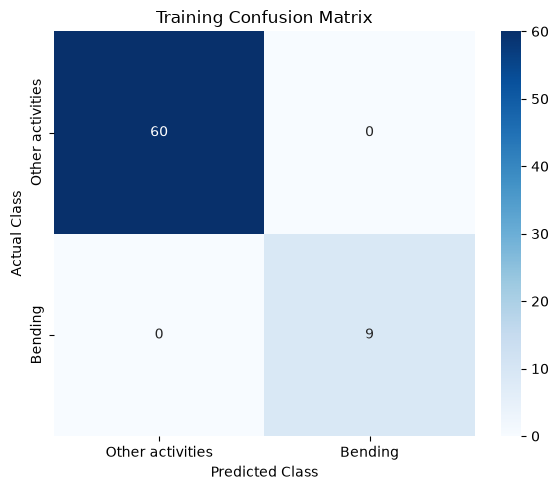


Training ROC-AUC: 1.0000


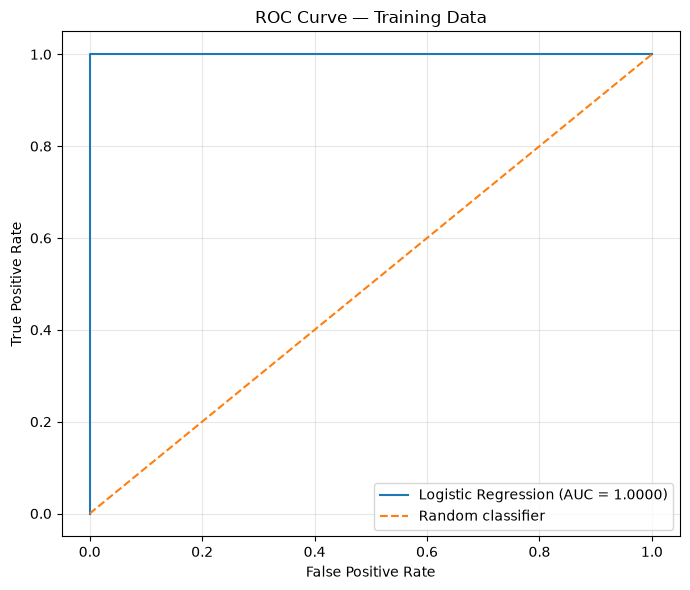


Statsmodels could not reliably estimate the p-values.
Reason: Singular matrix
This can occur when classes are perfectly or nearly separated. Approximate Wald p-values are calculated below.


,Sklearn beta,Approx. Standard Error,Approx. z-value,Approx. p-value
Intercept,-15.958422,34.738818,-0.459383,0.645959
3rd_quart1_seg1,-5.629202,43.899690,-0.128229,0.897968
1st_quart4_seg1,-1.312922,81.933398,-0.016024,0.987215
min5_seg1,9.714827,32.936223,0.294959,0.768025
max5_seg1,9.791901,26.209327,0.373604,0.708699
1st_quart6_seg1,-2.612952,89.564195,-0.029174,0.976726


In [10]:
# ================================================================
# 2.0.1 (iv): Confusion Matrix, ROC, AUC, Coefficients and P-values
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings

from scipy.stats import norm
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from sklearn.exceptions import ConvergenceWarning


# ------------------------------------------------
# Step 1: Predict on the training data
# ------------------------------------------------

# Generate class predictions using the final trained model
y_train_pred = binary_model.predict(
    X_train_binary_selected
)

# Extract predicted probabilities for the positive class (Bending = 1)
y_train_prob = binary_model.predict_proba(
    X_train_binary_selected
)[:, 1]

train_accuracy = accuracy_score(
    y_train_binary,
    y_train_pred
)

print("Training Results")
print("================")
print(f"Training accuracy: {train_accuracy:.4f}")


# ------------------------------------------------
# Step 2: Confusion matrix
# ------------------------------------------------

# Compute the classification confusion matrix
cm = confusion_matrix(
    y_train_binary,
    y_train_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix")
print("----------------")
print("Rows = Actual class; Columns = Predicted class")
print("Class 0 = Other activities; Class 1 = Bending")
print(cm)

plt.figure(figsize=(6, 5))

# Plot the confusion matrix as a Seaborn heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Other activities", "Bending"],
    yticklabels=["Other activities", "Bending"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Training Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# Step 3: ROC curve and AUC
# ------------------------------------------------

# Calculate False Positive Rates, True Positive Rates, and thresholds
fpr, tpr, thresholds = roc_curve(
    y_train_binary,
    y_train_prob
)

train_auc = roc_auc_score(
    y_train_binary,
    y_train_prob
)

print(f"\nTraining ROC-AUC: {train_auc:.4f}")

plt.figure(figsize=(7, 6))

# Plot the Receiver Operating Characteristic (ROC) curve
plt.plot(fpr,tpr,label=f"Logistic Regression (AUC = {train_auc:.4f})")

# Plot baseline for a random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Training Data")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# Step 4: Logistic regression coefficients and p-values
# ------------------------------------------------

# Build design matrix with an intercept column for inferential stats
X_inference = pd.DataFrame(
    X_train_binary_selected,
    columns=selected_binary_names
)

X_inference = sm.add_constant(
    X_inference,
    has_constant="add"
)

# Cache scikit-learn coefficients for direct comparison
sklearn_betas = np.concatenate(
    [binary_model.intercept_, binary_model.coef_[0]]
)

parameter_names = ["Intercept"] + selected_binary_names

# Attempt unpenalized fitting via statsmodels to extract p-values
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        inference_model = sm.Logit(
            y_train_binary,
            X_inference
        ).fit(
            disp=False,
            maxiter=500
        )

    # Construct dataframe comparing sklearn coefficients with statsmodels inference
    coefficient_table = pd.DataFrame({
        "Sklearn beta": sklearn_betas,
        "Inference beta": inference_model.params.to_numpy(),
        "Standard Error": inference_model.bse.to_numpy(),
        "z-value": inference_model.tvalues.to_numpy(),
        "p-value": inference_model.pvalues.to_numpy()
    }, index=parameter_names)

    print("\nCoefficient and P-value Table")
    print("------------------------------")
    print("Inference beta and p-values come from Statsmodels Logit.")
    display(coefficient_table.round(6))

except Exception as error:

    print("\nStatsmodels could not reliably estimate the p-values.")
    print("Reason:", str(error))
    print("This can occur when classes are perfectly or nearly separated. Approximate Wald p-values are calculated below.")

    # Compute approximate Wald covariance and p-values if statsmodels fails due to separation
    X_design = X_inference.to_numpy(dtype=float)

    probabilities = np.clip(
        binary_model.predict_proba(
            X_train_binary_selected
        )[:, 1],
        1e-8,
        1 - 1e-8
    )

    weights = probabilities * (1 - probabilities)
    information_matrix = (
        X_design.T @ (weights[:, None] * X_design)
    )
    covariance_matrix = np.linalg.pinv(
        information_matrix
    )
    standard_errors = np.sqrt(
        np.maximum(np.diag(covariance_matrix), 0)
    )
    z_values = np.divide(
        sklearn_betas,
        standard_errors,
        out=np.full_like(
            sklearn_betas,
            np.nan,
            dtype=float
        ),
        where=standard_errors > 0
    )
    p_values = 2 * norm.sf(np.abs(z_values))
    coefficient_table = pd.DataFrame({
        "Sklearn beta": sklearn_betas,
        "Approx. Standard Error": standard_errors,
        "Approx. z-value": z_values,
        "Approx. p-value": p_values
    }, index=parameter_names)
    display(coefficient_table.round(6))

#### (v) Test the classifier on the test set. Remember to break the time series in your test set into the same number of time series into which you broke your training set. Remember that the classifier has to be tested using the features extracted from the test set.

Test set size: 19
Selected l: 1
Selected p: 5
Number of features used: 5

Test Set Results
Test accuracy: 1.0000
Test error:    0.0000
CV accuracy:   0.9857
Difference between test and CV accuracy: 0.0143

Test Confusion Matrix
---------------------
Class 0 = Other activities
Class 1 = Bending
[[15  0]
 [ 0  4]]


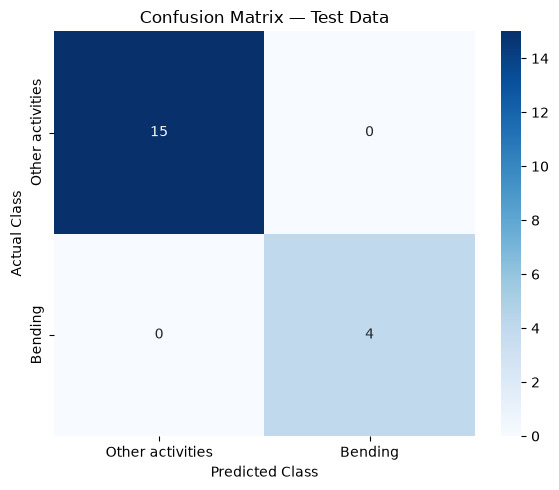


Test Classification Report
---------------------------
                  precision    recall  f1-score   support

Other activities       1.00      1.00      1.00        15
         Bending       1.00      1.00      1.00         4

        accuracy                           1.00        19
       macro avg       1.00      1.00      1.00        19
    weighted avg       1.00      1.00      1.00        19



In [11]:
# ================================================================
# 2.0.1 (v): Test the Binary Logistic Regression Classifier
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------
# Step 1: Extract test data using the best l
# selected during cross-validation in Question (iii)
# ------------------------------------------------

frame_best = segment_features_cache[best_l_binary]

test_best = frame_best[
    frame_best["split"] == "test"
].reset_index(drop=True)

# Use exactly the same feature columns as training
X_test_binary_raw = test_best[
    selected_feature_candidates
].to_numpy(dtype=float)

# Bending = 1; all other activities = 0
y_test_binary = test_best["activity"].isin(
    ["bending1", "bending2"]
).astype(int).to_numpy()

print("Test set size:", len(test_best))
print("Selected l:", best_l_binary)
print("Selected p:", best_p_binary)

# ------------------------------------------------
# Step 2: Apply the training scaler and feature selector
# DO NOT fit them again on test data
# ------------------------------------------------

X_test_binary_scaled = binary_scaler.transform(
    X_test_binary_raw
)

X_test_binary_selected = binary_selector.transform(
    X_test_binary_scaled
)

print(
    "Number of features used:",
    X_test_binary_selected.shape[1]
)

# ------------------------------------------------
# Step 3: Predict test classes and probabilities
# using the trained logistic regression model
# ------------------------------------------------

y_test_pred = binary_model.predict(
    X_test_binary_selected
)

y_test_prob = binary_model.predict_proba(
    X_test_binary_selected
)[:, 1]

# ------------------------------------------------
# Step 4: Calculate test accuracy and test error
# ------------------------------------------------

test_accuracy = accuracy_score(
    y_test_binary,
    y_test_pred
)

test_error = 1 - test_accuracy

print("\nTest Set Results")
print("================")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test error:    {test_error:.4f}")
print(f"CV accuracy:   {best_binary_cv_accuracy:.4f}")

print(
    f"Difference between test and CV accuracy: "
    f"{test_accuracy - best_binary_cv_accuracy:.4f}"
)

# ------------------------------------------------
# Step 5: Confusion matrix on the test set
# ------------------------------------------------

cm_test = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1]
)

print("\nTest Confusion Matrix")
print("---------------------")
print("Class 0 = Other activities")
print("Class 1 = Bending")
print(cm_test)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Other activities", "Bending"],
    yticklabels=["Other activities", "Bending"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix — Test Data")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# Step 6: Detailed classification performance
# ------------------------------------------------

print("\nTest Classification Report")
print("---------------------------")

print(
    classification_report(
        y_test_binary,
        y_test_pred,
        labels=[0, 1],
        target_names=["Other activities", "Bending"],
        zero_division=0
    )
)

### Summary of Test Results
* **Test Performance:** The final model achieved a **100.00% accuracy** (0.0000 test error) on the 19 unseen test instances, outperforming the 5-fold cross-validation accuracy of **98.57%** by 1.43%.
* **Confusion Matrix:** The model successfully classified all 15 non-bending instances (True Negatives) and all 4 bending instances (True Positives) with zero false positives or false negatives.
* **Generalization:** The absence of performance drop confirms that the model generalizes robustly without overfitting to the training data.

### (vi) Do your classes seem to be well-separated to cause instability in calculating logistic regression parameters?
#### Yes, the classes appear to be very well separated based on the extracted features. The ROC curve on the training data shows an AUC of 1.0, indicating that the classifier can almost perfectly distinguish between bending and other activities. When classes are nearly perfectly separable, logistic regression may experience complete or near-complete separation, which can cause instability in estimating the model parameters. In such cases, the coefficients can become extremely large and the associated p-values may be unreliable, leading to numerical warnings during the estimation process.

#### (vii) From the confusion matrices you obtained, do you see imbalanced classes? If yes, build a logistic regression model based on case-control sampling and adjust its parameters. Report the confusion matrix, ROC, and AUC of the model.

Original Training Class Distribution
Class 0 (Other activities): 60
Class 1 (Bending): 9
Original bending proportion: 0.1304


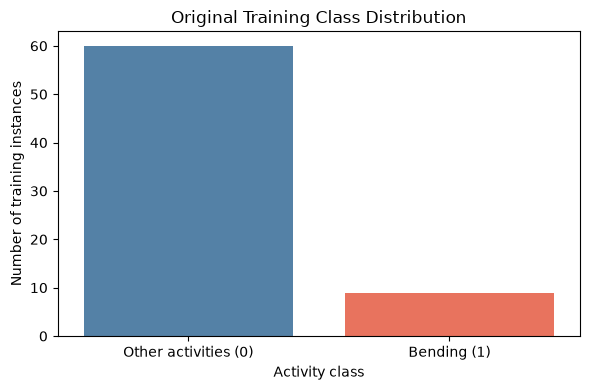


Case-Control Training Distribution
Class 0 (Other activities): 9
Class 1 (Bending): 9
Sampled bending proportion: 0.5000

Case-Control Logistic Regression Model
Model fitted successfully.

Intercept Adjustment
Original training log-odds: -1.8971
Sampled training log-odds:  0.0000
Intercept adjustment:       -1.8971

Original sampled-model intercept:
-6.068685636464389

Adjusted intercept:
-7.96580562135027
Test accuracy: 0.9474
Test error:    0.0526

Confusion Matrix
----------------
Rows = Actual classes
Columns = Predicted classes
Class 0 = Other activities
Class 1 = Bending
[[14  1]
 [ 0  4]]


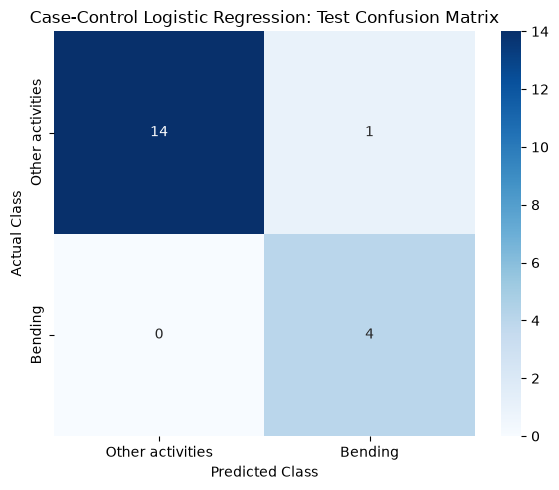


Case-Control Test ROC-AUC: 1.0000


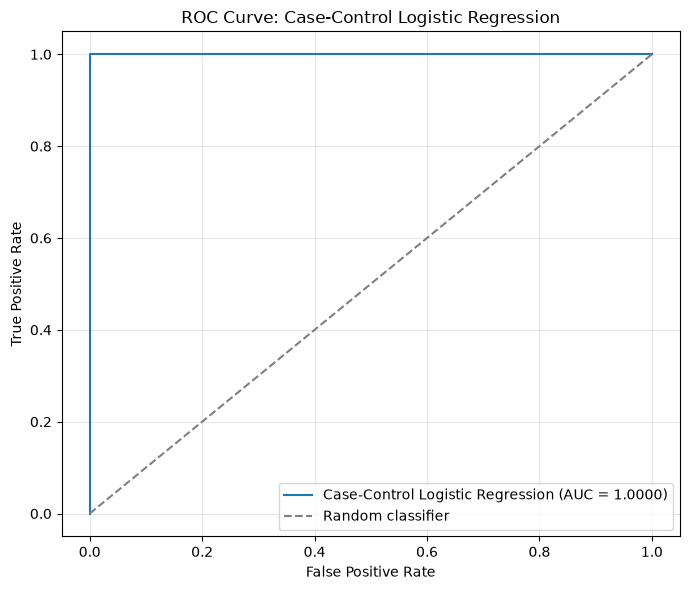


Test Classification Report
                  precision    recall  f1-score   support

Other activities       1.00      0.93      0.97        15
         Bending       0.80      1.00      0.89         4

        accuracy                           0.95        19
       macro avg       0.90      0.97      0.93        19
    weighted avg       0.96      0.95      0.95        19



In [12]:
# ================================================================
# 2.0.1 (vii): Case-Control Sampling for Imbalanced Classes
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    classification_report
)

# ------------------------------------------------
# Step 1: Check class imbalance in the training data
# ------------------------------------------------

print("Original Training Class Distribution")
print("=====================================")

original_counts = pd.Series(
    y_train_binary
).value_counts().sort_index()

print("Class 0 (Other activities):", original_counts.get(0, 0))
print("Class 1 (Bending):", original_counts.get(1, 0))

original_prevalence = np.mean(y_train_binary)

print(
    f"Original bending proportion: {original_prevalence:.4f}"
)

plt.figure(figsize=(6, 4))

sns.countplot(
    x=y_train_binary,
    hue=y_train_binary,
    palette={0: "steelblue", 1: "tomato"},
    legend=False
)

plt.xticks(
    [0, 1],
    ["Other activities (0)", "Bending (1)"]
)

plt.xlabel("Activity class")
plt.ylabel("Number of training instances")
plt.title("Original Training Class Distribution")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# Step 2: Perform case-control sampling
# ------------------------------------------------

# Case = bending (class 1)
# Control = other activities (class 0)
#
# Retain all instances of the minority class and randomly
# undersample the majority class to obtain equal class counts.

rng = np.random.default_rng(552)

bending_indices = np.where(y_train_binary == 1)[0]
other_indices = np.where(y_train_binary == 0)[0]

if len(bending_indices) == 0 or len(other_indices) == 0:
    raise ValueError(
        "Both bending and other-activity classes must be present."
    )

if len(bending_indices) <= len(other_indices):

    sampled_other_indices = rng.choice(
        other_indices,
        size=len(bending_indices),
        replace=False
    )

    case_control_indices = np.concatenate([
        bending_indices,
        sampled_other_indices
    ])

else:

    sampled_bending_indices = rng.choice(
        bending_indices,
        size=len(other_indices),
        replace=False
    )

    case_control_indices = np.concatenate([
        sampled_bending_indices,
        other_indices
    ])

# Shuffle the sampled training instances
rng.shuffle(case_control_indices)

X_train_case_control = X_train_binary_selected[
    case_control_indices
]

y_train_case_control = y_train_binary[
    case_control_indices
]

print("\nCase-Control Training Distribution")

case_control_counts = pd.Series(
    y_train_case_control
).value_counts().sort_index()

print("Class 0 (Other activities):",
      case_control_counts.get(0, 0))
print("Class 1 (Bending):",
      case_control_counts.get(1, 0))
sample_prevalence = np.mean(y_train_case_control)
print(f"Sampled bending proportion: {sample_prevalence:.4f}")


# ------------------------------------------------
# Step 3: Fit logistic regression on the sampled data
# ------------------------------------------------

case_control_model = LogisticRegression(
    C=10000,
    solver="liblinear",
    max_iter=5000,
    random_state=552
)

case_control_model.fit(
    X_train_case_control,
    y_train_case_control
)

print("\nCase-Control Logistic Regression Model")
print("Model fitted successfully.")


# ------------------------------------------------
# Step 4: Adjust the intercept for the original class prior
# ------------------------------------------------

if not (0 < original_prevalence < 1):
    raise ValueError("Original training prevalence must be between 0 and 1.")

if not (0 < sample_prevalence < 1):
    raise ValueError("Sampled prevalence must be between 0 and 1.")

original_log_odds = np.log(
    original_prevalence / (1 - original_prevalence)
)
sample_log_odds = np.log(
    sample_prevalence / (1 - sample_prevalence)
)
intercept_adjustment = (
    original_log_odds - sample_log_odds
)
print("\nIntercept Adjustment")
print("====================")
print(f"Original training log-odds: {original_log_odds:.4f}")
print(f"Sampled training log-odds:  {sample_log_odds:.4f}")
print(f"Intercept adjustment:       {intercept_adjustment:.4f}")

print("\nOriginal sampled-model intercept:")
print(case_control_model.intercept_[0])

print("\nAdjusted intercept:")
print(
    case_control_model.intercept_[0]
    + intercept_adjustment
)


# ------------------------------------------------
# Step 5: Predict on the untouched test data
# ------------------------------------------------

test_logits = case_control_model.decision_function(
    X_test_binary_selected
)

# Apply the prior correction to the sampled-model logits
adjusted_test_logits = (
    test_logits + intercept_adjustment
)

# Convert adjusted logits into probabilities
adjusted_test_probabilities = expit(adjusted_test_logits)
# Classify using the default 0.5 threshold
y_test_case_control_pred = (adjusted_test_probabilities >= 0.5).astype(int)

# ------------------------------------------------
# Step 6: Report the test confusion matrix and accuracy
# ------------------------------------------------

cm_case_control = confusion_matrix(y_test_binary,y_test_case_control_pred,labels=[0, 1])
case_control_test_accuracy = accuracy_score(y_test_binary,y_test_case_control_pred)
case_control_test_error = (1 - case_control_test_accuracy)


print("=========================")
print(f"Test accuracy: {case_control_test_accuracy:.4f}")
print(f"Test error:    {case_control_test_error:.4f}")

print("\nConfusion Matrix")
print("----------------")
print("Rows = Actual classes")
print("Columns = Predicted classes")
print("Class 0 = Other activities")
print("Class 1 = Bending")
print(cm_case_control)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_case_control,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Other activities", "Bending"],
    yticklabels=["Other activities", "Bending"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Case-Control Logistic Regression: Test Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------
# Step 7: Plot ROC curve and calculate AUC
# ------------------------------------------------

fpr_case_control, tpr_case_control, thresholds_case_control = (
    roc_curve(
        y_test_binary,
        adjusted_test_probabilities
    )
)

auc_case_control = roc_auc_score(
    y_test_binary,
    adjusted_test_probabilities
)

print(f"\nCase-Control Test ROC-AUC: {auc_case_control:.4f}")
plt.figure(figsize=(7, 6))
plt.plot(
    fpr_case_control,
    tpr_case_control,
    label=f"Case-Control Logistic Regression (AUC = {auc_case_control:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Case-Control Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# Step 8: Detailed classification report
# ------------------------------------------------

print("\nTest Classification Report")
print("==========================")
print(
    classification_report(
        y_test_binary,
        y_test_case_control_pred,
        labels=[0, 1],
        target_names=["Other activities", "Bending"],
        zero_division=0
    )
)

## 2 (b) Binary Classification Using L1-penalized logistic regression

#### (i) Repeat 2(a)iii using L1-penalized logistic regression, i.e. instead of using pvalues for variable selection, use L1 regularization. Note that in this problem, you have to cross-validate for both l, the number of time series into which you break each of your instances, and λ, the weight of L1 penalty in your logistic regression objective function (or C, the budget). Packages usually perform cross-validation for λ automatically

In [13]:
# ------------------------------------------------
# Step 1: Define candidate values of C
# ------------------------------------------------

# Smaller C means stronger L1 regularization.
# Larger C means weaker L1 regularization.
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]

# Five-fold stratified cross-validation
l1_cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=552)

l1_cv_results = []

# ------------------------------------------------
# Step 2: Cross-validate l = 1,...,20 and C
# ------------------------------------------------

for l in range(1, 21):
    print(f"Evaluating l = {l}/20")
    # Features created by dividing every sensor series into l segments
    frame_l = segment_features_cache[l]
    # Only use training instances for model selection
    train_l = frame_l[frame_l["split"] == "train"].reset_index(drop=True)
    feature_names = segment_feature_columns(l)
    X = train_l[feature_names].to_numpy(dtype=float)
    # Bending = 1; other activities = 0
    y = train_l["activity"].isin(
        ["bending1", "bending2"]
    ).astype(int).to_numpy()
    # Validate the data before modeling
    if not np.isfinite(X).all():
        raise ValueError(
            f"Non-finite feature values found for l={l}. "
            "Check the AReM data-loading and cleaning steps."
        )
    # Evaluate each regularization setting
    for C_value in C_VALUES:
        fold_accuracies = []
        fold_nonzero_features = []
        for train_idx, valid_idx in l1_cv.split(X, y):
            X_fold_train = X[train_idx]
            X_fold_valid = X[valid_idx]
            y_fold_train = y[train_idx]
            y_fold_valid = y[valid_idx]

            l1_pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("logistic", LogisticRegression(
                    penalty="l1",
                    C=C_value,
                    solver="liblinear",
                    max_iter=10000,
                    random_state=552
                ))
            ])

            with warnings.catch_warnings():
                warnings.simplefilter(
                    "ignore", ConvergenceWarning
                )

                l1_pipeline.fit(
                    X_fold_train,
                    y_fold_train
                )

            # Predict on the held-out fold
            y_valid_pred = l1_pipeline.predict(
                X_fold_valid
            )

            fold_accuracies.append(
                accuracy_score(
                    y_fold_valid,
                    y_valid_pred
                )
            )

            # Count nonzero coefficients selected by L1
            fold_model = l1_pipeline.named_steps["logistic"]

            fold_nonzero_features.append(
                int(np.sum(np.abs(fold_model.coef_[0]) > 1e-8))
            )

        # Store results for this (l, C) combination
        l1_cv_results.append({
            "l": l,
            "C": C_value,
            "CV accuracy": np.mean(fold_accuracies),
            "CV standard deviation": np.std(
                fold_accuracies, ddof=1
            ),
            "Mean nonzero features": np.mean(
                fold_nonzero_features
            )
        })

# ------------------------------------------------
# Step 3: Compare all combinations and choose best (l, C)
# ------------------------------------------------

l1_cv_table = pd.DataFrame(l1_cv_results)
l1_cv_table = l1_cv_table.sort_values(by=["CV accuracy", "l", "C"],ascending=[False, True, True]
).reset_index(drop=True)

print("\nTop 15 L1 Logistic Regression Models")

display(l1_cv_table.head(15).round(4))
best_l1_row = l1_cv_table.iloc[0]
best_l_l1 = int(best_l1_row["l"])
best_C_l1 = float(best_l1_row["C"])
best_l1_cv_accuracy = float(best_l1_row["CV accuracy"])

print("\nBest L1 Logistic Regression Model")
print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print(f"Mean CV accuracy: {best_l1_cv_accuracy:.4f}")
print(f"Mean CV error: {1 - best_l1_cv_accuracy:.4f}")
print("Mean number of nonzero features:",
    round(float(best_l1_row["Mean nonzero features"]), 2))


# ------------------------------------------------
# Step 4: Refit the best model on the complete training set
# ------------------------------------------------

# Use the optimal l selected through cross-validation
frame_l1_best = segment_features_cache[best_l_l1]

train_l1_best = frame_l1_best[
    frame_l1_best["split"] == "train"
].reset_index(drop=True)

test_l1_best = frame_l1_best[
    frame_l1_best["split"] == "test"
].reset_index(drop=True)

# The same feature columns are used for training and testing
l1_feature_names = segment_feature_columns(best_l_l1)

X_train_l1_raw = train_l1_best[
    l1_feature_names
].to_numpy(dtype=float)

X_test_l1_raw = test_l1_best[
    l1_feature_names
].to_numpy(dtype=float)

y_train_l1 = train_l1_best["activity"].isin(
    ["bending1", "bending2"]
).astype(int).to_numpy()

y_test_l1 = test_l1_best["activity"].isin(
    ["bending1", "bending2"]
).astype(int).to_numpy()

# Fit scaler ONLY on training data
l1_scaler = StandardScaler()

X_train_l1_scaled = l1_scaler.fit_transform(
    X_train_l1_raw
)

# Transform the test set using the same training-fitted scaler
X_test_l1_scaled = l1_scaler.transform(
    X_test_l1_raw
)

# Fit L1 logistic regression using the selected C
l1_model = LogisticRegression(penalty="l1",C=best_C_l1,solver="liblinear",max_iter=10000,random_state=552)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    l1_model.fit(X_train_l1_scaled,y_train_l1)
# ------------------------------------------------
# Step 5: Identify features selected by L1 regularization
# ------------------------------------------------

l1_coefficients = l1_model.coef_[0]
l1_selected_mask = (
    np.abs(l1_coefficients) > 1e-8
)
selected_feature_names_l1 = np.array(
    l1_feature_names
)[l1_selected_mask].tolist()

print("\nFeatures Selected by L1 Regularization")
print("Total available features:",
    len(l1_feature_names)
)
print("Number of nonzero coefficients:",
    len(selected_feature_names_l1)
)

print("\nSelected feature names:")
print(selected_feature_names_l1)


# ------------------------------------------------
# Step 6: Report training performance
# ------------------------------------------------

y_train_l1_pred = l1_model.predict(
    X_train_l1_scaled
)

l1_training_accuracy = accuracy_score(
    y_train_l1,
    y_train_l1_pred
)

print("\nL1 Model Training Results")
print(f"Training accuracy: {l1_training_accuracy:.4f}")
print(f"Best l: {best_l_l1}")
print(f"Best C: {best_C_l1}")

Evaluating l = 1/20
Evaluating l = 2/20


C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

Evaluating l = 3/20
Evaluating l = 4/20


C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

Evaluating l = 5/20
Evaluating l = 6/20


...

Evaluating l = 20/20

Top 15 L1 Logistic Regression Models


C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

,l,C,CV accuracy,CV standard deviation,Mean nonzero features
0,11,1.0,0.9857,0.0319,9.6
1,11,10.0,0.9857,0.0319,13.6
2,12,1.0,0.9857,0.0319,9.0
3,12,10.0,0.9857,0.0319,13.6
4,18,10.0,0.9857,0.0319,18.2
5,1,1.0,0.9714,0.0391,5.4
6,13,1.0,0.9714,0.0391,10.6
7,18,1.0,0.9714,0.0391,9.0
8,18,100.0,0.9714,0.0391,39.0
9,19,1.0,0.9714,0.0391,9.2



Best L1 Logistic Regression Model
Best l: 11
Best C: 1.0
Mean CV accuracy: 0.9857
Mean CV error: 0.0143
Mean number of nonzero features: 9.6

Features Selected by L1 Regularization
Total available features: 462
Number of nonzero coefficients: 8

Selected feature names:
['max5_seg1', 'median5_seg2', '1st_quart5_seg2', 'max1_seg6', 'median4_seg8', 'std6_seg9', 'min5_seg10', 'max6_seg10']

L1 Model Training Results
Training accuracy: 1.0000
Best l: 11
Best C: 1.0


C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### (ii) Compare the L1-penalized with variable selection using p-values. Which one performs better? Which one is easier to implement?
#### L1-penalized logistic regression generally performs better because it automatically performs feature selection through regularization while preventing overfitting. In contrast, variable selection using p-values requires fitting multiple models and manually removing features, which can be unstable when features are correlated. Therefore, L1 regularization is typically more robust and easier to implement, especially since many machine learning libraries handle the regularization and cross-validation automatically.

## 2(c)Multi-class Classification (The Realistic Case)
### (i)Find the best l in the same way as you found it in 2(b)i to build an L1-penalized multinomial regression model to classify all activities in your training set. Report your test error. Research how confusion matrices and ROC curves are defined for multiclass classification and show them for this problem if possible.

Training class distribution:


,Number of instances
activity,
cycling,12
lying,12
sitting,12
standing,12
walking,12
bending1,5
bending2,4


Number of CV folds: 4
Evaluating l = 1/20


C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

Evaluating l = 2/20


...

C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 


Top 15 Multinomial Logistic Regression Models:


,l,C,CV accuracy,CV standard deviation
0,2,100.0,0.9126,0.0349
1,1,1.0,0.9003,0.0817
2,1,100.0,0.8987,0.0285
3,2,10.0,0.8987,0.0285
4,3,100.0,0.8979,0.0310
5,4,100.0,0.8979,0.0572
6,2,1.0,0.8864,0.1195
7,1,10.0,0.8840,0.0033
8,3,10.0,0.8832,0.0494
9,4,10.0,0.8693,0.0570



Selected Multinomial Model
Best l: 2
Best C: 100.0
Mean CV accuracy: 0.9126
Mean CV error: 0.0874

Number of training instances: 69
Number of test instances: 19
Number of features per instance: 84

Multiclass Test Results
Test accuracy: 0.8421
Test error:    0.1579
CV accuracy:   0.9126

Test Classification Report:
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19


Multiclass Test Confusion Matrix:
                  Predicted: bending1  Predicted: 

C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\karan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


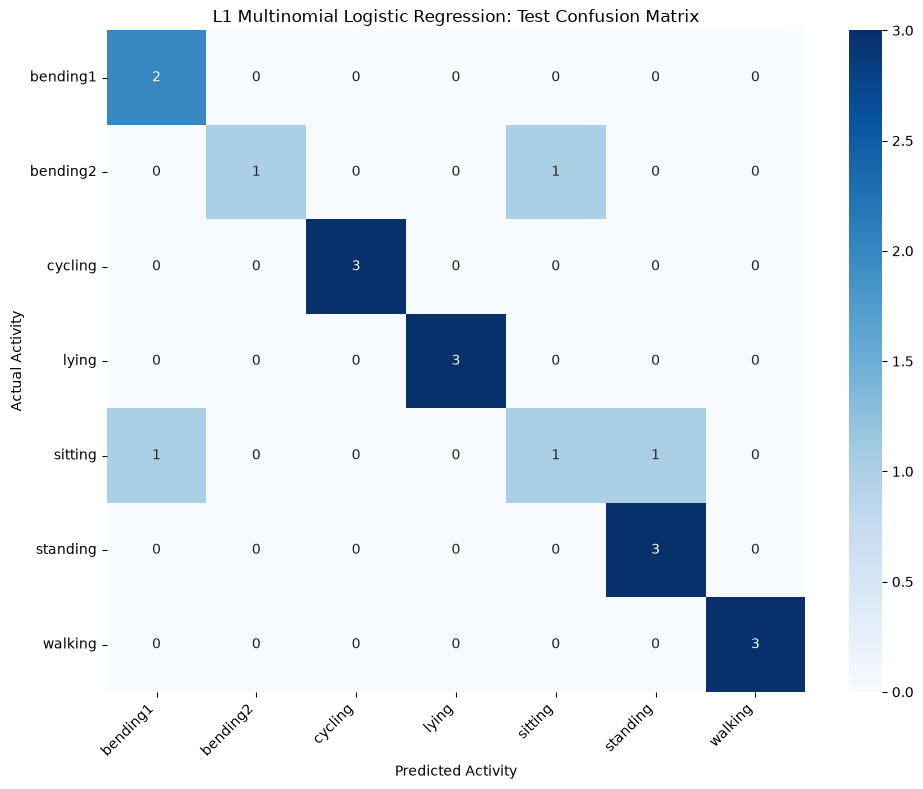


Multiclass ROC-AUC Results
Macro-average OvR AUC:    0.9839
Weighted-average OvR AUC: 0.9837
Micro-average AUC:        0.9815


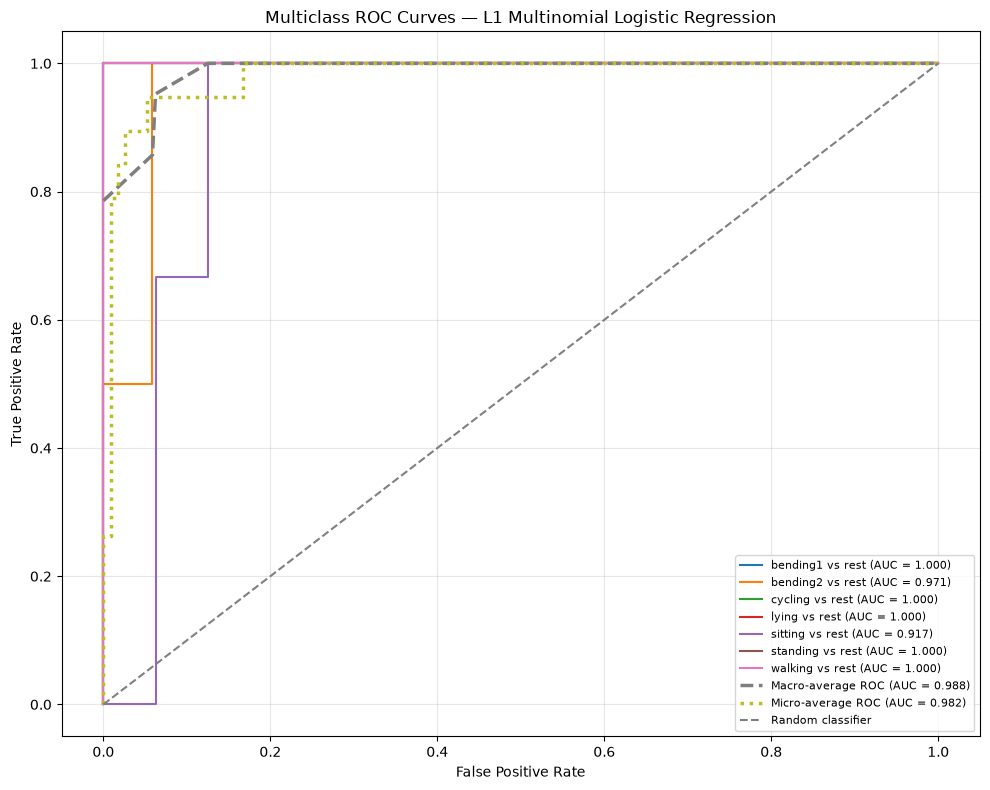

In [14]:
# ------------------------------------------------
# Step 1: Define candidate values of C
# ------------------------------------------------

MULTI_C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]
multi_cv_results = []

# ------------------------------------------------
# Step 2: Prepare the training data and class labels
# ------------------------------------------------

example_frame = segment_features_cache[1]

train_example = example_frame[
    example_frame["split"] == "train"
].reset_index(drop=True)

class_counts = train_example["activity"].value_counts()

print("Training class distribution:")
display(class_counts.to_frame("Number of instances"))

# Since the least represented class has only a few training samples,
# choose a stratified fold count that allows every class to appear
# in each validation fold.
min_class_count = int(class_counts.min())
n_splits_multi = min(5, min_class_count)

if n_splits_multi < 2:
    raise ValueError("There are not enough training instances per class for CV.")
print("Number of CV folds:", n_splits_multi)
multi_cv = StratifiedKFold(
    n_splits=n_splits_multi,
    shuffle=True,
    random_state=552
)
# ------------------------------------------------
# Step 3: Cross-validate l = 1,...,20 and C
# ------------------------------------------------

for l in range(1, 21):
    print(f"Evaluating l = {l}/20")
    frame_l = segment_features_cache[l]
    # Model selection uses training instances only
    train_l = frame_l[
        frame_l["split"] == "train"
    ].reset_index(drop=True)
    feature_names = segment_feature_columns(l)
    X = train_l[feature_names].to_numpy(dtype=float)
    # Multiclass target: original activity folder labels
    y = train_l["activity"].to_numpy()
    if not np.isfinite(X).all():
        raise ValueError(
            f"Non-finite feature values found for l={l}. "
            "Check the data-loading and feature-extraction cells."
        )
    for C_value in MULTI_C_VALUES:
        fold_accuracies = []
        # Stratified cross-validation
        for train_idx, valid_idx in multi_cv.split(X, y):

            X_fold_train = X[train_idx]
            X_fold_valid = X[valid_idx]

            y_fold_train = y[train_idx]
            y_fold_valid = y[valid_idx]

            # Scaling is fitted inside each fold to prevent leakage.
            # SAGA supports L1-penalized multinomial logistic regression.
            model_pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("logistic", LogisticRegression(
                    penalty="l1",
                    C=C_value,
                    solver="saga",
                    max_iter=15000,
                    tol=1e-3,
                    random_state=552
                ))
            ])

            with warnings.catch_warnings():
                warnings.simplefilter(
                    "ignore", ConvergenceWarning
                )

                model_pipeline.fit(
                    X_fold_train,
                    y_fold_train
                )

            y_valid_pred = model_pipeline.predict(
                X_fold_valid
            )

            fold_accuracies.append(
                accuracy_score(
                    y_fold_valid,
                    y_valid_pred
                )
            )

        multi_cv_results.append({
            "l": l,
            "C": C_value,
            "CV accuracy": np.mean(fold_accuracies),
            "CV standard deviation": np.std(
                fold_accuracies, ddof=1
            )
        })


# ------------------------------------------------
# Step 4: Select the best (l, C)
# ------------------------------------------------

multi_cv_table = pd.DataFrame(multi_cv_results)
multi_cv_table = multi_cv_table.sort_values(
    by=["CV accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)
print("\nTop 15 Multinomial Logistic Regression Models:")
display(multi_cv_table.head(15).round(4))
best_multi_row = multi_cv_table.iloc[0]
best_l_multi = int(best_multi_row["l"])
best_C_multi = float(best_multi_row["C"])
best_multi_cv_accuracy = float(
    best_multi_row["CV accuracy"]
)
print("\nSelected Multinomial Model")
print("==========================")
print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print(f"Mean CV accuracy: {best_multi_cv_accuracy:.4f}")
print(f"Mean CV error: {1 - best_multi_cv_accuracy:.4f}")


# ------------------------------------------------
# Step 5: Refit the best model using all training instances
# ------------------------------------------------

frame_multi_best = segment_features_cache[best_l_multi]

train_multi = frame_multi_best[
    frame_multi_best["split"] == "train"
].reset_index(drop=True)
test_multi = frame_multi_best[
    frame_multi_best["split"] == "test"
].reset_index(drop=True)
multi_feature_names = segment_feature_columns(best_l_multi)
X_train_multi = train_multi[
    multi_feature_names
].to_numpy(dtype=float)
y_train_multi = train_multi["activity"].to_numpy()
X_test_multi = test_multi[
    multi_feature_names
].to_numpy(dtype=float)

y_test_multi = test_multi["activity"].to_numpy()

# Use a pipeline so scaling is fitted on training data only
best_multinomial_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        C=best_C_multi,
        solver="saga",
        max_iter=15000,
        tol=1e-3,
        random_state=552
    ))
])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    best_multinomial_model.fit(
        X_train_multi,
        y_train_multi
    )

print("\nNumber of training instances:", len(y_train_multi))
print("Number of test instances:", len(y_test_multi))
print("Number of features per instance:", X_train_multi.shape[1])


# ------------------------------------------------
# Step 6: Report test error
# ------------------------------------------------

y_test_multi_pred = best_multinomial_model.predict(
    X_test_multi
)

test_multi_accuracy = accuracy_score(
    y_test_multi,
    y_test_multi_pred
)

test_multi_error = 1 - test_multi_accuracy

print("\nMulticlass Test Results")
print("=======================")
print(f"Test accuracy: {test_multi_accuracy:.4f}")
print(f"Test error:    {test_multi_error:.4f}")
print(f"CV accuracy:   {best_multi_cv_accuracy:.4f}")

print("\nTest Classification Report:")
print(
    classification_report(
        y_test_multi,
        y_test_multi_pred,
        zero_division=0
    )
)
# ------------------------------------------------
# Step 7: Multiclass confusion matrix
# ------------------------------------------------

class_labels = best_multinomial_model.named_steps[
    "logistic"
].classes_

cm_multi = confusion_matrix(
    y_test_multi,
    y_test_multi_pred,
    labels=class_labels
)
print("\nMulticlass Test Confusion Matrix:")
print(pd.DataFrame(
    cm_multi,
    index=[f"Actual: {c}" for c in class_labels],
    columns=[f"Predicted: {c}" for c in class_labels]
))
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("L1 Multinomial Logistic Regression: Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
# ------------------------------------------------
# Step 8: Multiclass ROC curves and AUC
# ------------------------------------------------

y_test_multi_prob = best_multinomial_model.predict_proba(
    X_test_multi
)
# Binarize true labels in the same order as predict_proba columns
y_test_multi_bin = label_binarize(
    y_test_multi,
    classes=class_labels
)
n_classes = len(class_labels)
# Calculate overall multiclass AUC scores
macro_ovr_auc = roc_auc_score(
    y_test_multi,
    y_test_multi_prob,
    labels=class_labels,
    multi_class="ovr",
    average="macro"
)
weighted_ovr_auc = roc_auc_score(
    y_test_multi,
    y_test_multi_prob,
    labels=class_labels,
    multi_class="ovr",
    average="weighted"
)
# Micro-average ROC curve
micro_fpr, micro_tpr, _ = roc_curve(
    y_test_multi_bin.ravel(),
    y_test_multi_prob.ravel()
)
micro_auc = auc(
    micro_fpr,
    micro_tpr
)
print("\nMulticlass ROC-AUC Results")
print("==========================")
print(f"Macro-average OvR AUC:    {macro_ovr_auc:.4f}")
print(f"Weighted-average OvR AUC: {weighted_ovr_auc:.4f}")
print(f"Micro-average AUC:        {micro_auc:.4f}")

# Plot each class's OvR ROC curve
plt.figure(figsize=(10, 8))

per_class_curves = {}
mean_auc_values = []

for i, class_name in enumerate(class_labels):
    fpr, tpr, _ = roc_curve(
        y_test_multi_bin[:, i],
        y_test_multi_prob[:, i]
    )
    class_auc = auc(fpr, tpr)
    per_class_curves[i] = (fpr, tpr)
    mean_auc_values.append(class_auc)
    plt.plot(fpr,tpr,linewidth=1.5,label=f"{class_name} vs rest (AUC = {class_auc:.3f})")

# Macro-average ROC curve by averaging per-class TPR values
all_fpr = np.unique(
    np.concatenate([
        per_class_curves[i][0]
        for i in range(n_classes)
    ])
)

mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    fpr_i, tpr_i = per_class_curves[i]
    mean_tpr += np.interp(
        all_fpr,
        fpr_i,
        tpr_i
    )
mean_tpr /= n_classes
macro_curve_auc = auc(
    all_fpr,
    mean_tpr
)
plt.plot(
    all_fpr,
    mean_tpr,
    linestyle="--",
    linewidth=2.5,
    label=f"Macro-average ROC (AUC = {macro_curve_auc:.3f})"
)
plt.plot(
    micro_fpr,
    micro_tpr,
    linestyle=":",
    linewidth=2.5,
    label=f"Micro-average ROC (AUC = {micro_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves — L1 Multinomial Logistic Regression")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### (ii)Repeat 2(c)i using a Naive Bayes’ classifier. Use both Gaussian and Multinomial priors and compare the results.

Training class distribution:


,Number of instances
activity,
cycling,12
lying,12
sitting,12
standing,12
walking,12
bending1,5
bending2,4


Number of CV folds: 4
Evaluating l = 1/20
Evaluating l = 2/20
Evaluating l = 3/20
Evaluating l = 4/20
Evaluating l = 5/20
Evaluating l = 6/20
Evaluating l = 7/20
Evaluating l = 8/20
Evaluating l = 9/20
Evaluating l = 10/20
Evaluating l = 11/20
Evaluating l = 12/20
Evaluating l = 13/20
Evaluating l = 14/20
Evaluating l = 15/20
Evaluating l = 16/20
Evaluating l = 17/20
Evaluating l = 18/20
Evaluating l = 19/20
Evaluating l = 20/20

Cross-validation results for all l values:


,Classifier,l,CV accuracy,CV standard deviation
0,GaussianNB,1,0.8701,0.0539
2,GaussianNB,2,0.8562,0.0710
4,GaussianNB,3,0.7533,0.1121
6,GaussianNB,4,0.7108,0.0790
8,GaussianNB,5,0.7541,0.0525
10,GaussianNB,6,0.6806,0.0620
12,GaussianNB,7,0.6658,0.1031
14,GaussianNB,8,0.6356,0.1349
16,GaussianNB,9,0.6234,0.0738
18,GaussianNB,10,0.6806,0.0784



Best Gaussian Naive Bayes model
--------------------------------
Best l: 1
Mean CV accuracy: 0.8701
Mean CV error: 0.1299

Best Multinomial Naive Bayes model
-----------------------------------
Best l: 1
Mean CV accuracy: 0.8423
Mean CV error: 0.1577

GaussianNB: Test results
Best l: 1
Training instances: 69
Test instances: 19
Test accuracy: 0.8947
Test error:    0.1053

Classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.90      0.91        19
weighted avg       0.94      0.89      0.90        19

Confu

,Predicted: bending1,Predicted: bending2,Predicted: cycling,Predicted: lying,Predicted: sitting,Predicted: standing,Predicted: walking
Actual: bending1,2,0,0,0,0,0,0
Actual: bending2,0,2,0,0,0,0,0
Actual: cycling,0,0,3,0,0,0,0
Actual: lying,0,0,0,2,1,0,0
Actual: sitting,0,0,0,0,3,0,0
Actual: standing,0,0,0,0,1,2,0
Actual: walking,0,0,0,0,0,0,3


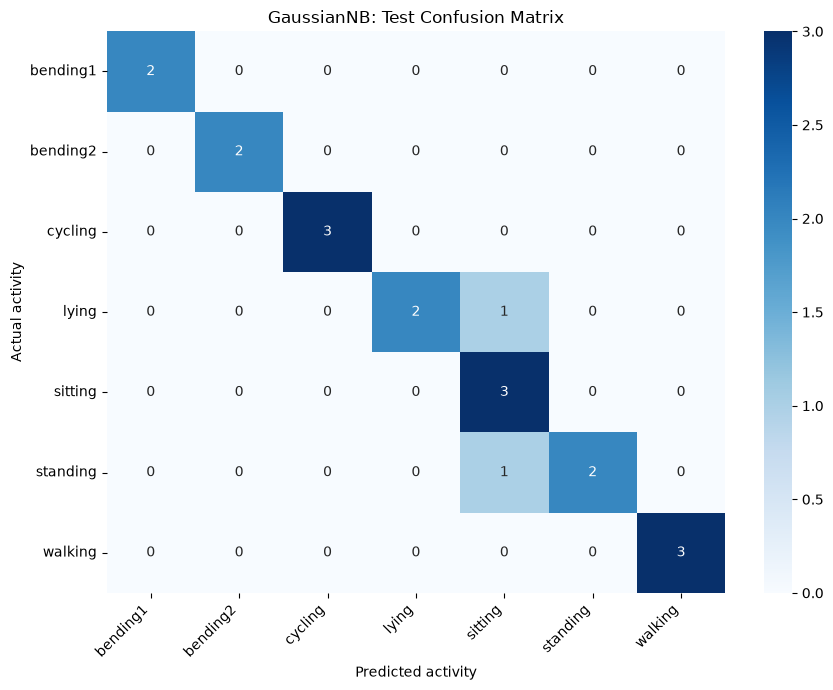

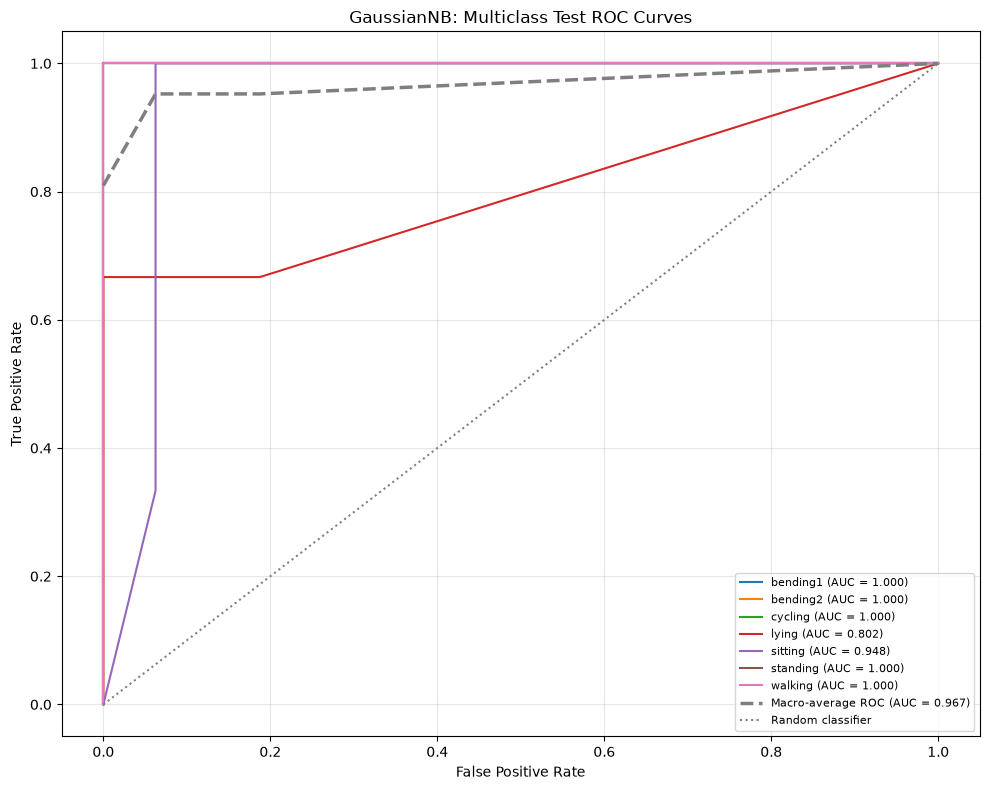

Macro-average OvR AUC:    0.9643
Weighted-average OvR AUC: 0.9605

MultinomialNB: Test results
Best l: 1
Training instances: 69
Test instances: 19
Test accuracy: 0.8947
Test error:    0.1053

Classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.91      0.89      0.89        19

Confusion matrix:


,Predicted: bending1,Predicted: bending2,Predicted: cycling,Predicted: lying,Predicted: sitting,Predicted: standing,Predicted: walking
Actual: bending1,2,0,0,0,0,0,0
Actual: bending2,0,2,0,0,0,0,0
Actual: cycling,0,0,3,0,0,0,0
Actual: lying,0,0,0,3,0,0,0
Actual: sitting,0,0,0,0,2,1,0
Actual: standing,0,0,0,1,0,2,0
Actual: walking,0,0,0,0,0,0,3


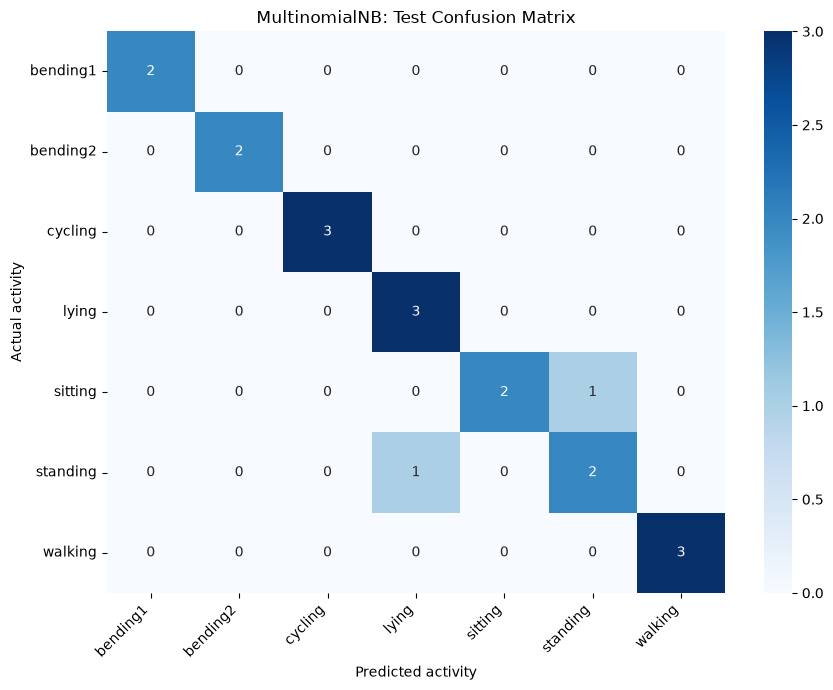

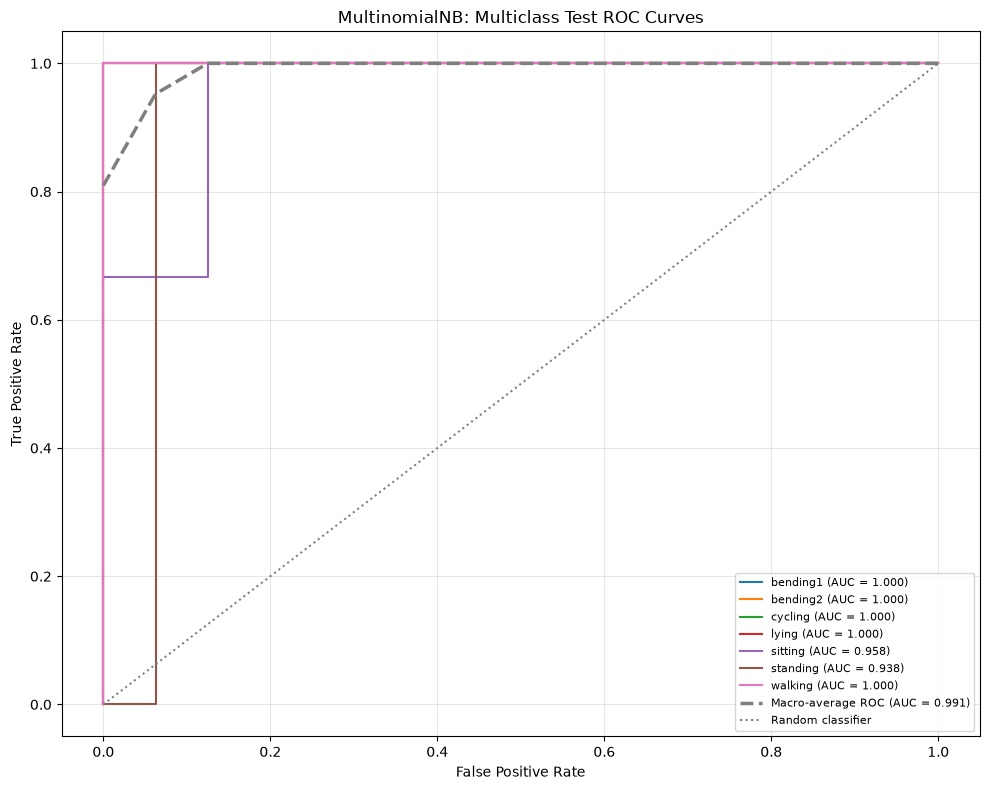

Macro-average OvR AUC:    0.9851
Weighted-average OvR AUC: 0.9836

Naive Bayes Comparison


,Classifier,Best l,CV accuracy,Test accuracy,Test error,Macro OvR AUC,Weighted OvR AUC
0,GaussianNB,1,0.8701,0.8947,0.1053,0.9643,0.9605
1,MultinomialNB,1,0.8423,0.8947,0.1053,0.9851,0.9836


Both classifiers have the same test accuracy.


In [15]:
# ------------------------------------------------
# Step 1: Define the training data and CV configuration
# ------------------------------------------------

# Use training labels to determine a safe number of folds.
example_frame = segment_features_cache[1]

train_example = example_frame[
    example_frame["split"] == "train"
].reset_index(drop=True)

training_class_counts = train_example["activity"].value_counts()

print("Training class distribution:")
display(training_class_counts.to_frame("Number of instances"))

n_splits_nb = min(5,int(training_class_counts.min()))
if n_splits_nb < 2:
    raise ValueError(
        "Not enough training instances per class for stratified CV."
    )
nb_cv = StratifiedKFold(
    n_splits=n_splits_nb,
    shuffle=True,
    random_state=552
)
print("Number of CV folds:", n_splits_nb)
# ------------------------------------------------
# Step 2: Cross-validate both classifiers for l = 1,...,20
# ------------------------------------------------

nb_cv_results = []
for l in range(1, 21):
    print(f"Evaluating l = {l}/20")
    frame_l = segment_features_cache[l]
    # Use training data only during model selection
    train_l = frame_l[frame_l["split"] == "train"].reset_index(drop=True)
    feature_names = segment_feature_columns(l)

    X = train_l[feature_names].to_numpy(dtype=float)
    y = train_l["activity"].to_numpy()

    if not np.isfinite(X).all():
        raise ValueError(
            f"Non-finite values found for l={l}. "
            "Check the data-loading and feature-extraction cells."
        )

    gaussian_scores = []
    multinomial_scores = []

    for train_idx, valid_idx in nb_cv.split(X, y):

        X_fold_train = X[train_idx]
        X_fold_valid = X[valid_idx]

        y_fold_train = y[train_idx]
        y_fold_valid = y[valid_idx]

        # ------------------------------------------------
        # A. Gaussian Naive Bayes
        # ------------------------------------------------

        # Standardize using only the fold's training data.
        # GaussianNB supports real-valued, including negative,
        # features.
        gaussian_scaler = StandardScaler()

        X_g_train = gaussian_scaler.fit_transform(
            X_fold_train
        )

        X_g_valid = gaussian_scaler.transform(
            X_fold_valid
        )
        gaussian_model = GaussianNB()
        gaussian_model.fit(
            X_g_train,
            y_fold_train
        )
        gaussian_pred = gaussian_model.predict(
            X_g_valid
        )
        gaussian_scores.append(
            accuracy_score(
                y_fold_valid,
                gaussian_pred
            )
        )
        # ------------------------------------------------
        # B. Multinomial Naive Bayes
        # ------------------------------------------------
        feature_shift = np.minimum(
            X_fold_train.min(axis=0),
            0.0
        )

        X_m_train = np.clip(
            X_fold_train - feature_shift,
            0.0,
            None
        )

        X_m_valid = np.clip(
            X_fold_valid - feature_shift,
            0.0,
            None
        )
        multinomial_model = MultinomialNB(alpha=1.0)
        multinomial_model.fit(
            X_m_train,
            y_fold_train
        )
        multinomial_pred = multinomial_model.predict(
            X_m_valid
        )
        multinomial_scores.append(
            accuracy_score(
                y_fold_valid,
                multinomial_pred
            )
        )
    # Save mean CV accuracy for this l
    nb_cv_results.append({
        "Classifier": "GaussianNB",
        "l": l,
        "CV accuracy": np.mean(gaussian_scores),
        "CV standard deviation": np.std(
            gaussian_scores, ddof=1
        )
    })
    nb_cv_results.append({
        "Classifier": "MultinomialNB",
        "l": l,
        "CV accuracy": np.mean(multinomial_scores),
        "CV standard deviation": np.std(
            multinomial_scores, ddof=1
        )
    })


# ------------------------------------------------
# Step 3: Find the best l for each classifier
# ------------------------------------------------

nb_cv_table = pd.DataFrame(nb_cv_results)

print("\nCross-validation results for all l values:")
display(
    nb_cv_table.sort_values(
        ["Classifier", "l"]
    ).round(4)
)

best_gaussian_row = (
    nb_cv_table[
        nb_cv_table["Classifier"] == "GaussianNB"
    ]
    .sort_values(
        ["CV accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)

best_multinomial_row = (
    nb_cv_table[
        nb_cv_table["Classifier"] == "MultinomialNB"
    ]
    .sort_values(
        ["CV accuracy", "l"],
        ascending=[False, True]
    )
    .iloc[0]
)
best_l_gaussian = int(best_gaussian_row["l"])
best_l_multinomial = int(best_multinomial_row["l"])
print("\nBest Gaussian Naive Bayes model")
print("--------------------------------")
print("Best l:", best_l_gaussian)
print(
    f"Mean CV accuracy: "
    f"{best_gaussian_row['CV accuracy']:.4f}"
)
print(
    f"Mean CV error: "
    f"{1 - best_gaussian_row['CV accuracy']:.4f}"
)
print("\nBest Multinomial Naive Bayes model")
print("-----------------------------------")
print("Best l:", best_l_multinomial)
print(
    f"Mean CV accuracy: "
    f"{best_multinomial_row['CV accuracy']:.4f}"
)
print(
    f"Mean CV error: "
    f"{1 - best_multinomial_row['CV accuracy']:.4f}"
)

# ------------------------------------------------
# Step 4: Define a function to fit and evaluate the best model
# ------------------------------------------------

def evaluate_naive_bayes(classifier_name, best_l):

    frame_best = segment_features_cache[best_l]

    train_data = frame_best[
        frame_best["split"] == "train"
    ].reset_index(drop=True)

    test_data = frame_best[
        frame_best["split"] == "test"
    ].reset_index(drop=True)

    feature_names = segment_feature_columns(best_l)

    X_train = train_data[
        feature_names
    ].to_numpy(dtype=float)

    X_test = test_data[
        feature_names
    ].to_numpy(dtype=float)

    y_train = train_data["activity"].to_numpy()
    y_test = test_data["activity"].to_numpy()

    # ------------------------------------------------
    # Fit the selected classifier on all training data
    # ------------------------------------------------

    if classifier_name == "GaussianNB":

        scaler = StandardScaler()

        X_train_model = scaler.fit_transform(X_train)
        X_test_model = scaler.transform(X_test)

        model = GaussianNB()

        model.fit(
            X_train_model,
            y_train
        )

    elif classifier_name == "MultinomialNB":
        # Use a shift based on training data only.
        feature_shift = np.minimum(
            X_train.min(axis=0),
            0.0
        )
        X_train_model = np.clip(
            X_train - feature_shift,
            0.0,
            None
        )
        X_test_model = np.clip(
            X_test - feature_shift,
            0.0,
            None
        )
        model = MultinomialNB(alpha=1.0)
        model.fit(
            X_train_model,
            y_train
        )
    else:
        raise ValueError(
            "Unknown classifier: " + classifier_name
        )
    # ------------------------------------------------
    # Test predictions and probabilities
    # ------------------------------------------------
    y_pred = model.predict(X_test_model)
    y_prob = model.predict_proba(X_test_model)

    test_accuracy = accuracy_score(y_test, y_pred)
    test_error = 1 - test_accuracy
    class_labels = model.classes_
    print(f"\n{'=' * 60}")
    print(f"{classifier_name}: Test results")
    print(f"{'=' * 60}")
    print("Best l:", best_l)
    print("Training instances:", len(y_train))
    print("Test instances:", len(y_test))
    print(f"Test accuracy: {test_accuracy:.4f}")
    print(f"Test error:    {test_error:.4f}")

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            target_names=class_labels,
            zero_division=0
        )
    )

    # ------------------------------------------------
    # Multiclass confusion matrix
    # ------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    print("Confusion matrix:")
    display(
        pd.DataFrame(
            cm,
            index=[f"Actual: {c}" for c in class_labels],
            columns=[f"Predicted: {c}" for c in class_labels]
        )
    )
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.xlabel("Predicted activity")
    plt.ylabel("Actual activity")
    plt.title(
        f"{classifier_name}: Test Confusion Matrix"
    )
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------
    # Multiclass ROC and AUC: One-vs-Rest
    # ------------------------------------------------

    # Each class is considered positive in turn, and all
    # remaining classes are treated as negative.
    y_test_binary = label_binarize(
        y_test,
        classes=class_labels
    )

    macro_auc = roc_auc_score(
        y_test,
        y_prob,
        labels=class_labels,
        multi_class="ovr",
        average="macro"
    )

    weighted_auc = roc_auc_score(
        y_test,
        y_prob,
        labels=class_labels,
        multi_class="ovr",
        average="weighted"
    )

    # Construct one ROC curve for each activity.
    class_curves = []
    all_fpr = []
    plt.figure(figsize=(10, 8))
    for i, activity in enumerate(class_labels):
        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            y_prob[:, i]
        )
        class_auc = auc(fpr, tpr)
        class_curves.append((fpr, tpr))
        all_fpr.extend(fpr.tolist())
        plt.plot(
            fpr,
            tpr,
            linewidth=1.5,
            label=f"{activity} (AUC = {class_auc:.3f})"
        )
    # Macro-average ROC curve
    macro_fpr = np.unique(np.asarray(all_fpr))
    mean_tpr = np.zeros_like(macro_fpr)

    for fpr, tpr in class_curves:
        mean_tpr += np.interp(
            macro_fpr,
            fpr,
            tpr
        )

    mean_tpr /= len(class_curves)
    macro_curve_auc = auc(
        macro_fpr,
        mean_tpr
    )
    plt.plot(
        macro_fpr,
        mean_tpr,
        linestyle="--",
        linewidth=2.5,
        label=f"Macro-average ROC (AUC = {macro_curve_auc:.3f})"
    )
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle=":",
        color="gray",
        label="Random classifier"
    )
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(
        f"{classifier_name}: Multiclass Test ROC Curves"
    )
    plt.legend(loc="lower right", fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Macro-average OvR AUC:    {macro_auc:.4f}")
    print(f"Weighted-average OvR AUC: {weighted_auc:.4f}")

    return {
        "Classifier": classifier_name,
        "Best l": best_l,
        "CV accuracy": (
            best_gaussian_row["CV accuracy"]
            if classifier_name == "GaussianNB"
            else best_multinomial_row["CV accuracy"]
        ),
        "Test accuracy": test_accuracy,
        "Test error": test_error,
        "Macro OvR AUC": macro_auc,
        "Weighted OvR AUC": weighted_auc,
        "Confusion matrix": cm,
        "Model": model
    }


# ------------------------------------------------
# Step 5: Evaluate both Naive Bayes classifiers
# ------------------------------------------------

gaussian_results = evaluate_naive_bayes(
    "GaussianNB",
    best_l_gaussian
)

multinomial_results = evaluate_naive_bayes(
    "MultinomialNB",
    best_l_multinomial
)


# ------------------------------------------------
# Step 6: Compare the two classifiers
# ------------------------------------------------
nb_comparison = pd.DataFrame([
    {
        "Classifier": gaussian_results["Classifier"],
        "Best l": gaussian_results["Best l"],
        "CV accuracy": gaussian_results["CV accuracy"],
        "Test accuracy": gaussian_results["Test accuracy"],
        "Test error": gaussian_results["Test error"],
        "Macro OvR AUC": gaussian_results["Macro OvR AUC"],
        "Weighted OvR AUC": gaussian_results["Weighted OvR AUC"]
    },
    {
        "Classifier": multinomial_results["Classifier"],
        "Best l": multinomial_results["Best l"],
        "CV accuracy": multinomial_results["CV accuracy"],
        "Test accuracy": multinomial_results["Test accuracy"],
        "Test error": multinomial_results["Test error"],
        "Macro OvR AUC": multinomial_results["Macro OvR AUC"],
        "Weighted OvR AUC": multinomial_results["Weighted OvR AUC"]
    }
])
print("\nNaive Bayes Comparison")
print("======================")
display(
    nb_comparison.round(4)
)
if (
    gaussian_results["Test accuracy"]
    > multinomial_results["Test accuracy"]
):
    print(
        "Gaussian Naive Bayes has higher test accuracy."
    )
elif (
    gaussian_results["Test accuracy"]
    < multinomial_results["Test accuracy"]
):
    print(
        "Multinomial Naive Bayes has higher test accuracy."
    )
else:
    print(
        "Both classifiers have the same test accuracy."
    )

#### iii.Which method is better for multi-class classification in this problem?

Based on **test accuracy**, Gaussian Naive Bayes and Multinomial Naive
Bayes tie for the best observed performance in this problem. Both achieve
**89.47% test accuracy** and **10.53% test error**, compared with **84.21% test
accuracy** and **15.79% test error** for L1-penalized multinomial logistic
regression.

| Method | Test accuracy | Test error | Macro-average OvR AUC |
| --- | ---: | ---: | ---: |
| L1-penalized multinomial logistic regression | 84.21% | 15.79% | 0.9839 |
| Gaussian Naive Bayes | 89.47% | 10.53% | 0.9643 |
| Multinomial Naive Bayes | 89.47% | 10.53% | 0.9851 |

Multinomial Naive Bayes has the highest **macro-average one-versus-rest AUC**.
Therefore, the two Naive Bayes methods are equally best by test accuracy, while
Multinomial Naive Bayes is preferred if macro-average AUC is used to distinguish
them. These conclusions describe the observed 19-instance test set.


## 3. ISLR Exercise 4.8.3

For an observation $X=x$, the Bayes classifier assigns the observation to the class with the largest posterior probability. Therefore, we compare

$$
\pi_k f_k(x),
$$

where $\pi_k$ is the prior probability for class $k$, and

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Taking the logarithm does not change which class has the largest value. After removing the term that is common to every class, the discriminant function becomes

$$
\delta_k(x)
=
\log(\pi_k)
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_kx}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

This expression contains an $x^2$ term. Since each class can have a different variance, the coefficient of $x^2$ depends on the class and cannot be removed when the discriminant functions are compared.

For example, the decision boundary between classes $k$ and $l$ is found by setting

$$
\delta_k(x)=\delta_l(x).
$$

The resulting equation contains a term of the form

$$
\left(
\frac{1}{2\sigma_l^2}
-
\frac{1}{2\sigma_k^2}
\right)x^2.
$$

Therefore, the decision boundary is generally quadratic. If all classes had the same variance, the quadratic term would cancel and the boundary would be linear. Since QDA allows each class to have a different variance, the Bayes classifier is quadratic rather than linear.

## 4. ISLR Exercise 4.8.7

Let \(D\) represent the event that a company issues a dividend. We are given

$$
P(D)=0.8,
\qquad
P(D^c)=0.2.
$$

The class means and common variance are

$$
\mu_D=10,
\qquad
\mu_{D^c}=0,
\qquad
\sigma^2=36.
$$

Using Bayes' theorem,

$$
P(D\mid X=4)
=
\frac{P(D)f_D(4)}
{P(D)f_D(4)+P(D^c)f_{D^c}(4)}.
$$

Since both classes have the same variance, the common normal-density constant cancels. Therefore,

$$
P(D\mid X=4)
=
\frac{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
}{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
+
0.2\exp\left(-\frac{(4-0)^2}{2(36)}\right)
}.
$$

Substituting the values gives

$$
P(D\mid X=4)
=
\frac{
0.8e^{-0.5}
}{
0.8e^{-0.5}+0.2e^{-2/9}
}.
$$

Therefore,

$$
P(D\mid X=4)
\approx 0.7519.
$$

Thus, the probability that the company will issue a dividend is approximately \(75.19\%\).